# CI connectivity learning, layer by layer

Can the CI test from feature sifting learn one layer's connectivity in a two-layer network when the other layer is
already good, and then both layers' at once? Test 1 fixes the input layer and learns the output layer's connectivity,
test 2 fixes the output layer and learns the input layer's, test 3 learns both, test 4 learns both with shadow
weights, test 5 repeats test 3 without regrowth after 100k steps, and test 6 repeats test 4 with an adaptive bar. The
problem is stationary and the CI test uses a fixed bar on $|w|$ (except in test 6), so no test involves label changes
or Autostep's trace. The baselines learn connectivity in test 4's setting by other methods.

**Problem.** Stationary parallel MNIST: each sample concatenates $T = 4$ independently drawn MNIST training images, and
each task's target is its own image's digit. The loss is the sum of each task's softmax cross-entropy, one sample per
step.

**Network.** $784T$ inputs → 50 LTU hidden units per task (0/1 forward, sigmoid derivative backward) → 10 linear
outputs per task (a group of 10 logits); at $T = 4$, 3136 → 200 → 40. Each hidden unit is assigned a task. Every
hidden and output unit has a bias, a weight on a constant input of 1 that is initialized and trained like its other
weights. Each layer is sparse and stored by unit: every hidden unit has 64 input slots and every output 20, besides the
bias. No unit reads the same source twice.
- **Inputs:** each pixel's value / 255, standardized by its running mean and variance (rate $10^{-3}$, bias-corrected so
  that early on they are averages over the samples seen so far), with the variance floored at 0.01, so $|x| \le 10$.
- **Hidden units:** $h = (b - m) / \sigma$ with $\sigma = \sqrt{\max(m(1 - m), 0.01)}$, where $b$ is the unit's bit and
  $m$ its running firing rate (rate $10^{-3}$, starting at 0.5), updated with each sample before it is used. The
  backward pass accounts for the statistics' dependence on the input weights: the error at $b$ is
  $(g - \mathbb{E}[g] - h\,\mathbb{E}[g h]) / \sigma$, where $g$ is the error arriving at $h$ and $\mathbb{E}[g]$,
  $\mathbb{E}[g h]$ are running means (rate $10^{-3}$) over previous steps. The $h\,\mathbb{E}[g h]$ term drops while
  the floor holds.

**Learner (network Autostep).** Autostep (`squared_inputs`, meta step-size 0.02, $\tau = 10^4$) on each layer that
learns, with every step-size starting at $\alpha_0 = 10^{-5}$. Learned input weights start $U(-\alpha_0, \alpha_0)$ and
learned output weights at 0, biases included. In tests 1 and 2 the other layer is fixed.

**CI connectivity learning.** Every unit of a learned layer tests each of its slots (not its bias) every step,
treating them as a linear problem: its error $\delta$ is the loss's gradient with respect to its pre-activation, and its inputs are its
sources' values. A slot is cut when $|w|$ is within one standard deviation of zero for a dead weight (one whose input is unrelated to
$\delta$) of the same age, $s(t) = \sqrt{\alpha\, \mathbb{E}[\delta^2] / 2 \cdot m_t}$, with $\mathbb{E}[\delta^2]$ the
unit's running mean of $\delta^2$ (horizon 1000 steps, bias-corrected) and $m_t = 1 - \prod_k (1 - a_k)^2$ the slot's
maturity before this step, which rises from 0 to 1 as the slot ages by $a_k$ at each step $k$. A cut slot reads a new
source for the same unit, drawn uniformly from those the unit isn't connected to, and restarts: weight 0, step-size
$\alpha_0$, no traces, maturity 0. Cutting starts at step 1.

**How a slot ages.** Test 2 compares three rules for $a$; tests 1 and 3–6 use the second.
- **By its own input: $a = \alpha x^2$.** The band grows with the evidence the slot has actually received. But a slot
  whose input never varies, such as a never-lit pixel, never ages, so its band stays 0 and it is never cut.
- **As a standardized input would, held back by $c$: $a = \alpha c$.** A standardized input has $\mathbb{E}[x^2] = 1$,
  so every slot ages at the same pace, and one whose input varies less, such as a never-lit pixel, falls behind a dead
  weight and is cut. $c = 1 - (1 - 10^{-3})^n$ is the share of the sources' running statistics that comes from data
  after $n$ samples; it holds aging back while standardization is still unreliable, over roughly the first 1000 steps.
  Every source exists from step 1, so $c$ is the same for all.
- **As a standardized input would: $a = \alpha$.** The same without holding back, relying instead on the sources'
  statistics being bias-corrected, so unbiased from step 1 (the pixels' are). Bias correction removes the pull of the
  starting values but not the noise of few samples: every pixel reads 0 at step 1, and a pixel reads 0 until it is
  first lit, so early on some slots age before their input has shown anything.

**Tests.**
- **Test 1, output layer.** The fixed input layer gives each hidden unit 64 random pixels of its own task's image, with
  LeCun uniform weights and bias, so every hidden unit is a random feature of one task. Each output learns which 20
  hidden units to read.
- **Test 2, input layer.** The fixed output layer gives each output 20 random hidden units of its own task, with LeCun
  uniform weights and bias. Each hidden unit learns which 64 pixels to read.
- **Test 3, both layers.** Nothing is fixed: each hidden unit learns which 64 pixels to read and each output which 20
  hidden units, at the same time.
- **Test 4, both layers with shadow weights.** Test 3, but each hidden unit gets a clear error from the start. One of
  its outgoing connections, chosen at random, carries a shadow weight of $\pm 1$ (random sign), which stands in for the
  real weight in the backward pass only, unless the real weight is larger in magnitude. The real weight starts at 0 and
  is trained and cut as usual. If a unit's shadow connection is cut, its largest-magnitude outgoing weight becomes its
  shadow, with that weight's sign (if they are all 0, a random one of them, with a random sign). A unit with no
  outgoing connections gets a shadow weight with a random sign on the first one it receives. Shadow weights aren't
  connections, so path purity ignores them. The idea: in test 3 every output weight starts at 0, so early on a hidden
  unit's error is weak and its objective unclear; a clear error, as in test 2, should let CI separate useful input
  connections from useless ones more cleanly.
- **Test 5, both layers without regrowth after 100k steps** (temporary). Test 3, but from step 100,001 a cut slot, in
  either layer, is left empty instead of regrowing: it reads a constant 0 and isn't a connection. If CI's connection
  path purity then rises toward 1, test 3's impurity comes from new connections still being added; if it stays put,
  from connections that are never cut. Random and ideal connectivity are test 3's runs, and the plot also shows test
  3's CI run.
- **Test 6, both layers with shadow weights and an adaptive bar.** Test 4, but each unit cuts a slot when
  $|w| < q\,s(t)$, with a bar $q$ of its own in place of 1: the utility threshold from
  `feature_sifting/corrupted_signal`. $q$ starts at 1 and never drops below it. At each step, every slot pulls $q$
  toward its $z = |w| / s(t)$ at its new maturity, weighted by the maturity it gained, so each slot casts one vote in
  total over its warm-up, and every slot still warming up pulls $q$ toward 1 at rate $(1 - m_t) / 10^5$. A unit whose
  established connections stand well clear of their bands raises its bar, so it cuts weak connections that a fixed
  bar keeps. Random connectivity is test 4's run and ideal connectivity test 3's; the plot also shows test 4's CI run.

**Baselines.** Each learns both layers' connectivity with shadow weights, as in test 4, and is plotted against test 4's
random connectivity and test 3's ideal connectivity.
- **Baseline 1, SET.** Every $P$ steps, in each layer, the share $\zeta$ of the layer's connections (biases aside) with
  the smallest $|w|$ is cut, and each unit regrows as many as it lost, as CI's cut slots do: a new source drawn
  uniformly from those the unit isn't connected to, weight 0, step-size $\alpha_0$, no traces. So every unit keeps its
  fan-in. Cut output slots move shadow weights as in test 4. Every combination of $P \in$ {100, 1000, 5000, 20,000}
  and $\zeta \in$ {0.01, 0.03, 0.1, 0.3} (0.3 is SET's default) runs once, on seed 0, and the plot shows each
  configuration's curve, unlabeled.
- **Baseline 2, layer-wide utility** (like continual backprop). Each connection has a utility, a trace of $|w|$:
  $u \leftarrow \lambda u + (1 - \lambda)|w|$, starting at 0. At every step, the share $r$ of the layer's connections
  with the lowest utility in the layer is cut, the count accumulating across steps, so a fraction of a connection per
  step adds up. As many new connections are made anywhere in the layer: each goes to a unit drawn uniformly from those
  below 4 times their starting fan-in (256 inputs per hidden unit, 80 per output), from a source that unit isn't
  connected to, so fan-ins change. A new connection starts like CI's cut slots (weight 0, step-size $\alpha_0$, no
  traces), with the median utility of the layer's connections. Biases have no utility and are never cut. Every
  combination of $r \in$ {10⁻⁵, 10⁻⁴, 10⁻³, 10⁻²} and $\lambda \in$ {0.9, 0.99, 0.999} runs once, on seed 0. To run
  faster, connections are cut and regrown only every 8 steps, while the utilities and the count of connections due to
  be cut update every step.
- **Baseline 3, per-unit utility.** Baseline 2 made local to each unit: each unit cuts the share $r$ of its own
  connections with the lowest utility among them, regrows as many itself, so every unit keeps its fan-in, and its new
  connections start with the median utility of its connections. The same combinations.
- **Baseline 4, DEEP R.** Each connection has a fixed sign $s$ and a magnitude $\theta = s w$, and goes dormant (is
  cut) as soon as $\theta < 0$. At every step, Autostep's gradient for each connection includes an L1 term $\lambda s$,
  which pulls $\theta$ toward 0, and after the update the weight gets Gaussian noise of standard deviation
  $\sqrt{2 \alpha T}$, with the weight's own step-size $\alpha$ in place of DEEP R's learning rate. Every 8 steps, each
  layer is refilled to its starting number of connections anywhere in the layer, as in baseline 2. A new connection
  has $\theta = 0$, a random sign, step-size $\alpha_0$ and no traces; a starting connection's sign is that of its
  starting weight (random for the output weights, which start at 0). Biases get neither L1 nor noise and are never cut.
  Every combination of $\lambda \in$ {10⁻⁵, 10⁻⁴, 10⁻³, 10⁻²} and $T \in$ {0, 10⁻⁷, 10⁻⁵, 10⁻³} runs once, on seed 0.

Each test has three runs (test 2 has one CI run per aging rule; in test 4, random connectivity and CI have shadow
weights and ideal connectivity is test 3's, without them; test 4's plot also shows test 3's CI run):
- **Random connectivity (baseline):** each learned layer's slots read sources drawn uniformly from all sources, and never
  change.
- **Ideal connectivity (reference):** each slot reads a source drawn uniformly from the unit's own task, and never
  changes.
- **CI (proposed):** starts from the baseline's connectivity (the same draw for each seed) and learns it.

**Metrics.** Online loss per task and online accuracy (over every task), on each sample before learning from it.
*Weight path purity* is the share of all input → hidden → output path weight (the product of $|w|$ along the path) that
starts and ends in the same task. *Connection path purity* is the same with every connection counted as 1, so every
path has equal weight; it is about $1/T$ with random connectivity and 1 with ideal connectivity. Biases aren't
connections, so neither counts them. Everything is recorded
at step 1, then averaged over each window of 2000 steps, and plotted as the mean over 5 seeds.
Seed $s$ gives every run the same images. 200k steps.

**Hypotheses** (for each test and, in test 2, each aging rule; over the last 10% of training, means over seeds):
- **H1:** CI's connection path purity is at least 0.9.
- **H2:** CI's online loss closes at least half the gap from random connectivity's loss to ideal connectivity's.
- **H3** (test 4 only): CI's connection path purity is higher than without shadow weights (test 3, 0.68).
- **H4** (test 6 only): CI's connection path purity is higher than with the fixed bar (test 4).

**Diagnostics if a hypothesis fails:** the fraction of slots cut per step over training, and how often own-task and
other-task slots are cut, to see whether useful connections are cut before they can establish.

In [2]:
import os
from typing import NamedTuple

os.environ.setdefault('XLA_PYTHON_CLIENT_PREALLOCATE', 'false')   # take GPU memory only as needed, to share the GPU

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [ ]:
# --- Problem ---
N_TASKS = 4
N_PIXELS = 28 * 28
N_CLASSES = 10

# --- Network ---
HIDDEN_PER_TASK = 50
N_INPUTS = N_TASKS * N_PIXELS
N_HIDDEN = N_TASKS * HIDDEN_PER_TASK                  # 200 at 4 tasks
N_OUTPUTS = N_TASKS * N_CLASSES
HIDDEN_FAN_IN = 64                   # input slots per hidden unit, besides its bias
OUTPUT_FAN_IN = 20                   # slots per output, besides its bias
STAT_RATE = 1e-3                     # rate of every running statistic: pixel moments, firing rates, error traces
VAR_FLOOR = 0.01                     # floor on the pixels' and the hidden units' variances

# --- Network Autostep ---
AUTOSTEP_INIT_STEP_SIZE = 1e-5       # alpha_0: every step-size starts here, and learned input weights U(-alpha_0, alpha_0)
AUTOSTEP_META_STEP_SIZE = 0.02
AUTOSTEP_TAU = 1e4

# --- CI ---
BAND_TRACE_HORIZON = 1_000           # horizon of each unit's running mean of delta^2
BAR_HORIZON = 100_000                # how slowly slots still warming up pull the adaptive bar down (test 6)

# --- Baselines ---
SPREAD_WIDTH = 4                     # baseline 2: each unit's slots, as a multiple of its starting fan-in
RESTRUCTURE_PERIOD = 8               # baselines 2-4: steps between regrowths (and cuts, in baselines 2-3)

# --- Training ---
NUM_STEPS = 200_000
N_SEEDS = 5
WINDOW = 2000                        # each window records its mean loss, accuracy and path purities

In [4]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
IMAGES = jnp.asarray(np.asarray(mnist.data, dtype=np.float32).reshape(-1, N_PIXELS) / 255.0)    # each pixel / 255
DIGITS = jnp.asarray(np.asarray(mnist.targets))


def next_sample(key):
    # One sample: an independent training image per task, concatenated, and each task's digit.
    index = jax.random.randint(key, (N_TASKS,), 0, IMAGES.shape[0])
    return IMAGES[index].reshape(-1), DIGITS[index]

In [5]:
INPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_PIXELS)
HIDDEN_TASK = jnp.repeat(jnp.arange(N_TASKS), HIDDEN_PER_TASK)     # each hidden unit's task
OUTPUT_TASK = jnp.repeat(jnp.arange(N_TASKS), N_CLASSES)
METRICS = ('loss', 'accuracy', 'weight purity', 'connection purity')


def path_purity(reads, feeds):
    # The share of all input -> hidden -> output path weight that starts and ends in the same task, from each hidden
    # unit's totals over its connections from every task's inputs (`reads`) and to every task's outputs (`feeds`), each
    # shaped (hidden unit, task).
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(1) * feeds.sum(1)), 1e-30)


def task_totals(net, value):
    # Each hidden unit's total of value(w) over its connections from every task's inputs and to every task's outputs.
    # value = |w| makes a path's weight the product of |w| along it (weight path purity); value = 1 counts every path
    # once (connection path purity). Biases (each layer's last column) aren't connections, so they're left out, and
    # neither are empty slots (source N_INPUTS or N_HIDDEN).
    reads = jnp.zeros((N_HIDDEN, N_TASKS)).at[jnp.arange(N_HIDDEN)[:, None], INPUT_TASK[net.src_in]].add(
        value(net.w_in[:, :-1]) * (net.src_in < N_INPUTS))
    feeds = jnp.zeros((N_HIDDEN, N_TASKS)).at[net.src_out, OUTPUT_TASK[:, None]].add(
        value(net.w_out[:, :-1]) * (net.src_out < N_HIDDEN))
    return reads, feeds

## Learner

In [6]:
AUTOSTEP = optax_idbd(meta_lr=AUTOSTEP_META_STEP_SIZE, init_lr=AUTOSTEP_INIT_STEP_SIZE, autostep=True,
                      tau=AUTOSTEP_TAU, version='squared_inputs')
LEARNED = {'input': (0,), 'output': (1,), 'both': (0, 1)}      # the layers each test learns: 0 input, 1 output
N_SOURCES = (N_INPUTS, N_HIDDEN)                                # each layer's possible sources
FAN_IN = (HIDDEN_FAN_IN, OUTPUT_FAN_IN)                         # each layer's starting fan-in


class Net(NamedTuple):
    # Both layers are stored by unit: slot k of unit u reads source src[u, k] with weight w[u, k], and the last column
    # of w is the unit's bias, its weight on a constant input of 1.
    w_in: jax.Array           # (hidden unit, slot + bias)
    src_in: jax.Array         # (hidden unit, slot) the pixel each slot reads
    w_out: jax.Array          # (output, slot + bias)
    src_out: jax.Array        # (output, slot) the hidden unit each slot reads
    opt: IDBDState            # Autostep's step-sizes and traces, for the learned layers' weights
    n_samples: jax.Array      # samples seen, for the pixel moments' bias correction
    pixel_mean: jax.Array     # (input,) running means of each pixel and of its square, before bias correction
    pixel_sq: jax.Array
    firing: jax.Array         # (hidden unit,) running firing rate
    g_mean: jax.Array         # (hidden unit,) running means of the error g arriving at h and of g h
    gh_mean: jax.Array
    delta_sq: tuple           # per learned layer, (unit,): running mean of delta^2, before bias correction (CI only)
    log_imm: tuple            # per learned layer, (unit, slot): log(1 - maturity), 0 at birth (CI only)
    key: jax.Array            # for regrowth (CI only)
    shadow: jax.Array         # (output, slot) the shadow weight on each output slot: +-1, or 0 where there is none
    q: tuple                  # per learned layer, (unit,): CI's bar, in standard deviations of a dead weight
    utility: tuple            # per learned layer, (unit, slot + bias): each connection's trace of |w| (baselines 2-3)
    pending: tuple            # per learned layer, (): connections due to be cut, carried over (baselines 2-3)
    sign: tuple               # per learned layer, (unit, slot + bias): each connection's fixed sign (baseline 4)


def draw_sources(key, fan_in, pool_size, offset):
    # Each unit's slots read distinct sources drawn uniformly from offset[unit] + [0, pool_size).
    picks = jax.vmap(lambda key: jax.random.choice(key, pool_size, (fan_in,), replace=False))(
        jax.random.split(key, len(offset)))
    return offset[:, None] + picks


def lecun(key, src):
    # LeCun uniform weights over each unit's slots and its bias.
    fan_in = src.shape[1] + 1
    return jax.random.uniform(key, (src.shape[0], fan_in), minval=-1.0, maxval=1.0) * np.sqrt(3 / fan_in)


def pixel_sources(key, own_task):
    # Each hidden unit's HIDDEN_FAN_IN slots read random pixels, of its own task's image if `own_task`.
    return (draw_sources(key, HIDDEN_FAN_IN, N_PIXELS, HIDDEN_TASK * N_PIXELS) if own_task else
            draw_sources(key, HIDDEN_FAN_IN, N_INPUTS, jnp.zeros(N_HIDDEN, jnp.int32)))


def hidden_sources(key, own_task):
    # Each output's OUTPUT_FAN_IN slots read random hidden units, of its own task if `own_task`.
    return (draw_sources(key, OUTPUT_FAN_IN, HIDDEN_PER_TASK, OUTPUT_TASK * HIDDEN_PER_TASK) if own_task else
            draw_sources(key, OUTPUT_FAN_IN, N_HIDDEN, jnp.zeros(N_OUTPUTS, jnp.int32)))


def small_input_weights(key):
    # Learned input weights and biases: U(-alpha_0, alpha_0).
    return jax.random.uniform(key, (N_HIDDEN, HIDDEN_FAN_IN + 1), minval=-1.0, maxval=1.0) * AUTOSTEP_INIT_STEP_SIZE


def new_net(key, w_in, src_in, w_out, src_out, learned):
    # A net with these layers, of which those in LEARNED[learned] are trained by Autostep. Every slot starts newborn.
    layers = tuple((w_in, w_out)[i] for i in LEARNED[learned])
    return Net(w_in, src_in, w_out, src_out, AUTOSTEP.init(layers), jnp.array(0), jnp.zeros(N_INPUTS),
               jnp.zeros(N_INPUTS), jnp.full(N_HIDDEN, 0.5), jnp.zeros(N_HIDDEN), jnp.zeros(N_HIDDEN),
               tuple(jnp.zeros(w.shape[0]) for w in layers), tuple(jnp.zeros(w.shape) for w in layers),
               jax.random.fold_in(key, 1), jnp.zeros(src_out.shape), tuple(jnp.ones(w.shape[0]) for w in layers),
               tuple(jnp.zeros(w.shape) for w in layers), tuple(jnp.zeros(()) for w in layers),
               tuple(jnp.where(w != 0, jnp.sign(w), jax.random.rademacher(jax.random.fold_in(key, 3 + k), w.shape,
                                                                          dtype=jnp.float32))
                     for k, w in enumerate(layers)))


def init_output_test(key, ideal):
    # Test 1. Fixed input layer: each hidden unit reads random pixels of its own task's image, with LeCun uniform
    # weights and bias. Learned output layer: each output reads random hidden units, of its own task if `ideal` and of
    # any task otherwise, with weights and bias starting at 0.
    in_key, weight_key, out_key = jax.random.split(key, 3)
    src_in = pixel_sources(in_key, True)
    return new_net(key, lecun(weight_key, src_in), src_in, jnp.zeros((N_OUTPUTS, OUTPUT_FAN_IN + 1)),
                   hidden_sources(out_key, ideal), 'output')


def init_input_test(key, ideal):
    # Test 2. Learned input layer: each hidden unit reads random pixels, of its own task's image if `ideal` and of any
    # image otherwise, with small weights and bias. Fixed output layer: each output reads random hidden units of its own
    # task, with LeCun uniform weights and bias.
    in_key, weight_key, out_key, out_weight_key = jax.random.split(key, 4)
    src_out = hidden_sources(out_key, True)
    return new_net(key, small_input_weights(weight_key), pixel_sources(in_key, ideal), lecun(out_weight_key, src_out),
                   src_out, 'input')


def init_both_test(key, ideal):
    # Test 3. Both layers learned: each hidden unit reads random pixels and each output random hidden units, of the
    # unit's own task if `ideal` and of any otherwise. Input weights and biases start small, output weights and biases
    # at 0.
    in_key, weight_key, out_key = jax.random.split(key, 3)
    return new_net(key, small_input_weights(weight_key), pixel_sources(in_key, ideal),
                   jnp.zeros((N_OUTPUTS, OUTPUT_FAN_IN + 1)), hidden_sources(out_key, ideal), 'both')


def reassign_shadows(shadow, w_out, src_out, key):
    # Every hidden unit with outgoing connections but no shadow weight gets one, on its largest-magnitude outgoing weight
    # (a random one if several tie, which only happens at 0), with that weight's sign, or a random sign if it is 0.
    w, src, shadow = w_out[:, :-1].ravel(), src_out.ravel(), shadow.ravel()
    has_shadow = jax.ops.segment_max(jnp.abs(shadow), src, N_HIDDEN) > 0
    tie_key, sign_key = jax.random.split(key)
    largest = jnp.abs(w) == jax.ops.segment_max(jnp.abs(w), src, N_HIDDEN)[src]
    draw = jnp.where(largest, jax.random.uniform(tie_key, w.shape), -1.0)
    chosen = (draw == jax.ops.segment_max(draw, src, N_HIDDEN)[src]) & ~has_shadow[src] & (src < N_HIDDEN)
    sign = jnp.where(w != 0, jnp.sign(w), jax.random.rademacher(sign_key, w.shape, dtype=jnp.float32))
    return jnp.where(chosen, sign, shadow).reshape(src_out.shape)


def init_shadow_test(key, ideal):
    # Test 4. Test 3's start, plus a shadow weight for every hidden unit with outgoing connections: since every output
    # weight is 0, it goes on one of them chosen at random, with a random sign.
    net = init_both_test(key, ideal)
    return net._replace(shadow=reassign_shadows(net.shadow, net.w_out, net.src_out, jax.random.fold_in(key, 2)))


def init_spread_test(key):
    # Baseline 2. Test 4's random start, with each unit's slots padded with empty ones (reading source N_INPUTS or
    # N_HIDDEN, a constant 0) to SPREAD_WIDTH times its starting fan-in, so connections can move between units.
    in_key, weight_key, out_key = jax.random.split(key, 3)
    extra = (SPREAD_WIDTH - 1) * HIDDEN_FAN_IN, (SPREAD_WIDTH - 1) * OUTPUT_FAN_IN
    w_in = small_input_weights(weight_key)
    w_in = jnp.concatenate([w_in[:, :-1], jnp.zeros((N_HIDDEN, extra[0])), w_in[:, -1:]], axis=1)
    src_in = jnp.pad(pixel_sources(in_key, False), ((0, 0), (0, extra[0])), constant_values=N_INPUTS)
    src_out = jnp.pad(hidden_sources(out_key, False), ((0, 0), (0, extra[1])), constant_values=N_HIDDEN)
    net = new_net(key, w_in, src_in, jnp.zeros((N_OUTPUTS, SPREAD_WIDTH * OUTPUT_FAN_IN + 1)), src_out, 'both')
    return net._replace(shadow=reassign_shadows(net.shadow, net.w_out, net.src_out, jax.random.fold_in(key, 2)))


def standardize_pixels(net, pixels):
    # Each pixel minus its running mean, over the square root of its running variance (floored), both updated with this
    # sample first and bias-corrected so that early on they are averages over the samples seen so far. Inputs don't
    # depend on any weights, so no gradient flows through them. Returns the inputs and the new running moments.
    n_samples = net.n_samples + 1
    pixel_mean = net.pixel_mean + STAT_RATE * (pixels - net.pixel_mean)
    pixel_sq = net.pixel_sq + STAT_RATE * (pixels ** 2 - net.pixel_sq)
    unbias = -jnp.expm1(n_samples * jnp.log1p(-STAT_RATE))         # 1 - (1 - STAT_RATE)^n
    mean = pixel_mean / unbias
    x = (pixels - mean) / jnp.sqrt(jnp.maximum(pixel_sq / unbias - mean ** 2, VAR_FLOOR))
    return x, {'n_samples': n_samples, 'pixel_mean': pixel_mean, 'pixel_sq': pixel_sq}


def network(net, x, labels, rate=STAT_RATE):
    # Forward and backward for one sample's standardized inputs x. Firing rates first move toward this sample's bits by
    # `rate`. Returns the loss, whether each task is classified correctly, each layer's source value per slot (then the
    # bias's input, 1), each layer's delta (the loss's gradient with respect to each unit's pre-activation) and, for the
    # hidden units, the new firing rates, the error g arriving at h, and h.
    # An empty slot reads source N_INPUTS (N_HIDDEN in the output layer), a constant 0.
    x_in = jnp.append(jnp.append(x, 0.0)[net.src_in], jnp.ones((N_HIDDEN, 1)), axis=1)
    z = jnp.sum(net.w_in * x_in, axis=1)
    bits = ltu(z)
    firing = net.firing + rate * (bits - net.firing)
    variance = firing * (1 - firing)
    scale = jnp.sqrt(jnp.maximum(variance, VAR_FLOOR))
    h = (bits - firing) / scale
    h_in = jnp.append(jnp.append(h, 0.0)[net.src_out], jnp.ones((N_OUTPUTS, 1)), axis=1)
    log_p = jax.nn.log_softmax(jnp.sum(net.w_out * h_in, axis=1).reshape(N_TASKS, N_CLASSES))
    delta_out = (jnp.exp(log_p) - jax.nn.one_hot(labels, N_CLASSES)).ravel()
    # The error reaching each hidden unit comes through the output weights, with the unit's shadow weight standing in
    # for the real weight on its slot unless the real one is larger in magnitude.
    feedback = jnp.where((net.shadow != 0) & (jnp.abs(net.w_out[:, :-1]) < 1.0), net.shadow, net.w_out[:, :-1])
    g = jnp.zeros(N_HIDDEN).at[net.src_out].add(feedback * delta_out[:, None])
    # Through the standardization, with the running means of g and g h standing in for E[g] and E[g h] (the h E[g h]
    # term drops while the variance floor holds), then through the LTU's surrogate slope.
    s = jax.nn.sigmoid(z)
    delta_hidden = (g - net.g_mean - jnp.where(variance > VAR_FLOOR, h * net.gh_mean, 0.0)) / scale * s * (1 - s)
    loss = -jnp.sum(log_p[jnp.arange(N_TASKS), labels])
    return loss, log_p.argmax(1) == labels, (x_in, h_in), (delta_hidden, delta_out), (firing, g, h)


def regrow(src, cut, key, n_sources, n_draws=None):
    # Each cut slot reads a new source for the same unit, drawn uniformly from those the unit isn't connected to (its
    # old source included), and no two of a unit's cut slots draw the same one. Each unit draws ranks among its
    # unconnected sources, keeps the first occurrence of each, and gives its k-th cut slot the k-th; fan-in + 16 draws
    # (the default) leave enough distinct ones with overwhelming probability. Rank r is the source r + (the number of
    # connected sources with at most r unconnected sources below them). Empty slots (source n_sources) aren't
    # connections.
    n_units, fan_in = src.shape
    n_draws = fan_in + 16 if n_draws is None else n_draws
    draws = jax.random.randint(key, (n_units, n_draws), 0, n_sources - jnp.sum(src < n_sources, axis=1, keepdims=True))
    earlier = jnp.arange(n_draws)[None, :] < jnp.arange(n_draws)[:, None]
    first = ~jnp.any((draws[:, :, None] == draws[:, None, :]) & earlier, axis=2)
    order = jnp.where(first, jnp.cumsum(first, axis=1) - 1, -1)
    rank = jnp.sum(jnp.where(order[:, None, :] == (jnp.cumsum(cut, axis=1) - 1)[:, :, None], draws[:, None, :], 0),
                   axis=2)
    free_below = src - jnp.sum(src[:, None, :] < src[:, :, None], axis=2)
    return jnp.where(cut, rank + jnp.sum(free_below[:, None, :] <= rank[:, :, None], axis=2), src)


def set_cut(w, n_samples, period, zeta):
    # SET's cut: at every `period`-th step, the share `zeta` of the layer's connections (biases aside) with the smallest
    # |w|, ties broken by position.
    magnitude = jnp.abs(w[:, :-1]).ravel()
    smallest = jnp.zeros(magnitude.size, bool).at[jnp.argsort(magnitude)].set(
        jnp.arange(magnitude.size) < jnp.round(zeta * magnitude.size))
    return jnp.pad(smallest.reshape(w.shape[0], -1) & (n_samples % period == 0), ((0, 0), (0, 1)))


def connections(src, n_sources):
    # Which of a layer's slots, then its bias, hold a connection: neither empty slots (source n_sources) nor the bias.
    return jnp.append(src < n_sources, jnp.zeros((len(src), 1), bool), axis=1)


def lowest(values, k):
    # Whether each entry is among the k lowest of its row, ties broken by position.
    order = jnp.argsort(values, axis=1)
    return jnp.zeros(values.shape, bool).at[jnp.arange(len(values))[:, None], order].set(
        jnp.arange(values.shape[1]) < k)


def spread(src, cut, key, n_sources, target):
    # Baseline 2's regrowth. Cut connections leave their slots empty, and the layer then regains as many connections as
    # it is short of `target`, each in a unit drawn uniformly from those with an empty slot, from a source that unit
    # isn't connected to. Units are drawn without replacement from 16 tickets each (fewer if a unit has fewer empty
    # slots), so a unit gains at most 16 per step and any shortfall carries over. Returns the new sources and which
    # slots got a new connection.
    src = jnp.where(cut, n_sources, src)
    empty = src == n_sources
    ticket_key, regrow_key = jax.random.split(key)
    tickets = jnp.where(jnp.arange(16) < empty.sum(1, keepdims=True), jax.random.uniform(ticket_key, (len(src), 16)),
                        jnp.inf)
    drawn = lowest(tickets.reshape(1, -1), target - jnp.sum(~empty)).reshape(tickets.shape) & jnp.isfinite(tickets)
    grown = empty & (jnp.cumsum(empty, axis=1) <= drawn.sum(1, keepdims=True))
    return regrow(src, grown, regrow_key, n_sources, n_draws=32), grown


def learn(net, pixels, labels, layer, prune, shadow=False, age='c', regrow_until=None, adaptive=False, set_rule=None,
          utility_rule=None, deep_r=None):
    # One online step: Autostep on the layers in LEARNED[layer] and then, if `prune`, every unit of each of them runs
    # its CI test on its slots, cutting and regrowing (until step `regrow_until`, if given), with slots aging by `age`
    # and the bar adapting if `adaptive`; with `shadow`, cut output slots also move shadow weights. With `set_rule`,
    # (period, zeta), SET's cut replaces the CI test, and with `utility_rule`, (local, rate, decay), baseline 3's
    # (local) or baseline 2's cut and regrowth do; with `deep_r`, (l1, temperature), DEEP R cuts at every step and
    # baseline 2's regrowth runs when `prune`. Returns the new net, the loss per task and the fraction of tasks
    # classified correctly.
    x, pixel_moments = standardize_pixels(net, pixels)
    loss, correct, sources, deltas, (firing, g, h) = network(net, x, labels)
    learned = LEARNED[layer]
    ws, srcs = [net.w_in, net.w_out], [net.src_in, net.src_out]
    source, delta = tuple(sources[i] for i in learned), [deltas[i] for i in learned]
    grads = tuple(d[:, None] * s for d, s in zip(delta, source))
    if deep_r is not None:
        # DEEP R's L1 on each connection's magnitude theta = s w, pulling it toward 0 (biases and empty slots aside).
        grads = tuple(g + deep_r[0] * net.sign[j] * connections(srcs[i], N_SOURCES[i])
                      for j, (g, i) in enumerate(zip(grads, learned)))
    updates, opt = AUTOSTEP.update((grads, None, source), net.opt, tuple(ws[i] for i in learned))
    for j, i in enumerate(learned):
        ws[i] = ws[i] + updates[j]
    net = net._replace(opt=opt, firing=firing, g_mean=net.g_mean + STAT_RATE * (g - net.g_mean),
                       gh_mean=net.gh_mean + STAT_RATE * (g * h - net.gh_mean), **pixel_moments)
    if deep_r is not None:
        # DEEP R, every step: Gaussian noise of standard deviation sqrt(2 alpha T) on each connection, alpha being its
        # step-size, and then every connection whose theta has turned negative goes dormant, leaving its slot empty
        # until the next regrowth, which also resets its step-size and traces.
        key, *noise_keys = jax.random.split(net.key, 1 + len(learned))
        for j, i in enumerate(learned):
            live = connections(srcs[i], N_SOURCES[i])
            ws[i] = ws[i] + live * jnp.sqrt(2.0 * jnp.exp(opt.beta[j]) * deep_r[1]) * jax.random.normal(
                noise_keys[j], ws[i].shape)
            dormant = live & (net.sign[j] * ws[i] < 0)
            srcs[i] = jnp.where(dormant[:, :-1], N_SOURCES[i], srcs[i])
            ws[i] = jnp.where(dormant, 0.0, ws[i])
            if shadow and i == 1:
                key, shadow_key = jax.random.split(key)
                net = net._replace(shadow=reassign_shadows(jnp.where(dormant[:, :-1], 0.0, net.shadow), ws[i],
                                                           srcs[i], shadow_key))
        net = net._replace(key=key)
    if utility_rule is not None:
        # Every step, pruned or not: each connection's utility, a trace of |w|, and the number of connections due to be
        # cut, the share `rate` of the layer's (or, if `local`, of each unit's) per step, carried over until they are.
        local, rate, decay = utility_rule
        net = net._replace(
            utility=tuple(decay * u + (1 - decay) * jnp.abs(ws[i]) for u, i in zip(net.utility, learned)),
            pending=tuple(p + rate * FAN_IN[i] * (1 if local else len(ws[i])) for p, i in zip(net.pending, learned)))
    if prune:
        # A slot is cut when |w| is within q standard deviations of a dead weight of the same age, q being the unit's bar
        # (1 unless `adaptive`). The band uses the maturity from before this step, so a slot always survives its first
        # step, and the bar is also from before this step. Biases are never cut.
        gain = 1.0 / BAND_TRACE_HORIZON
        unbias = -jnp.expm1(net.n_samples * jnp.log1p(-gain))       # so delta_sq reads unbiased from step 1
        # Each slot ages by alpha x^2 (age 'input'), alpha c ('c') or alpha ('alpha'), c being the share of the sources'
        # running statistics that comes from data. Cut slots restart: weight 0, step-size alpha_0, no traces, maturity 0.
        c = -jnp.expm1(net.n_samples * jnp.log1p(-STAT_RATE))
        key, *regrow_keys = jax.random.split(net.key, 1 + len(learned))
        delta_sq, log_imm, q, utility, pending, sign, beta, trace, v = [], [], [], [], [], [], [], [], []
        for j, i in enumerate(learned):
            delta_sq.append(net.delta_sq[j] + gain * (delta[j] ** 2 - net.delta_sq[j]))
            alpha = jnp.exp(opt.beta[j])
            band = jnp.sqrt(alpha * (delta_sq[j] / unbias)[:, None] / 2.0 * -jnp.expm1(net.log_imm[j]))
            utility.append(net.utility[j])
            pending.append(net.pending[j])
            sign.append(net.sign[j])
            if set_rule is not None:
                cut = set_cut(ws[i], net.n_samples, *set_rule)
            elif utility_rule is not None:
                # As many of the connections with the lowest utility, in the layer or, if `local`, in each unit, as
                # have come due. New connections start with the median utility of the existing ones, before the cut.
                used = connections(srcs[i], N_SOURCES[i])
                median = jnp.nanmedian(jnp.where(used, utility[j], jnp.nan), axis=1 if local else None, keepdims=True)
                n_cut = jnp.floor(pending[j])
                pending[j] = pending[j] - n_cut
                ranked = jnp.where(used, utility[j], jnp.inf)
                cut = used & (lowest(ranked, n_cut) if local else
                              lowest(ranked.reshape(1, -1), n_cut).reshape(ranked.shape))
            elif deep_r is not None:
                cut = jnp.zeros(ws[i].shape, bool)                   # DEEP R cuts at every step, above
            else:
                cut = (jnp.abs(ws[i]) < net.q[j][:, None] * band).at[:, -1].set(False)
            aging = {'input': alpha * source[j] ** 2, 'c': alpha * c, 'alpha': alpha}[age]
            d_log_imm = 2.0 * jnp.log1p(-jnp.minimum(aging, 1.0))
            q.append(net.q[j])
            if adaptive:
                # Each slot pulls the bar toward its z = |w| / s(t) at its new maturity, weighted by the maturity it
                # gained (one vote per slot over its warm-up), and each slot still warming up pulls it toward 1 at rate
                # (1 - m_t) / BAR_HORIZON. It never drops below 1.
                new_log_imm = net.log_imm[j] + d_log_imm
                new_band = jnp.sqrt(alpha * (delta_sq[j] / unbias)[:, None] / 2.0 * -jnp.expm1(new_log_imm))
                z = jnp.where(new_band > 0, jnp.abs(ws[i]) / new_band, 0.0)
                bar = net.q[j][:, None]
                pulls = (jnp.exp(net.log_imm[j]) * -jnp.expm1(d_log_imm) * (z - bar)
                         + jnp.exp(new_log_imm) / BAR_HORIZON * (1.0 - bar))
                q[j] = jnp.maximum(net.q[j] + jnp.sum(pulls[:, :-1], axis=1), 1.0)
            log_imm.append(jnp.where(cut, 0.0, net.log_imm[j] + d_log_imm))
            if deep_r is not None or (utility_rule is not None and not utility_rule[0]):
                srcs[i], grown = spread(srcs[i], cut[:, :-1], regrow_keys[j], N_SOURCES[i], len(ws[i]) * FAN_IN[i])
                cut = cut | jnp.pad(grown, ((0, 0), (0, 1)))           # every slot that changed restarts
            else:
                srcs[i] = regrow(srcs[i], cut[:, :-1], regrow_keys[j], N_SOURCES[i])
            if utility_rule is not None:
                utility[j] = jnp.where(cut, median, utility[j])
            if deep_r is not None:
                sign[j] = jnp.where(cut, jax.random.rademacher(jax.random.fold_in(regrow_keys[j], 1), cut.shape,
                                                               dtype=jnp.float32), sign[j])
            if regrow_until is not None:
                # After step `regrow_until`, a cut slot is left empty instead: it reads source N_SOURCES[i].
                srcs[i] = jnp.where(cut[:, :-1] & (net.n_samples > regrow_until), N_SOURCES[i], srcs[i])
            ws[i] = jnp.where(cut, 0.0, ws[i])
            beta.append(jnp.where(cut, opt.init_beta, opt.beta[j]))
            trace.append(jnp.where(cut, 0.0, opt.h[j]))
            v.append(jnp.where(cut, 0.0, opt.v[j]))
            if shadow and i == 1:
                # A cut slot loses its shadow weight, and a unit left without one gets a new one.
                key, shadow_key = jax.random.split(key)
                net = net._replace(shadow=reassign_shadows(jnp.where(cut[:, :-1], 0.0, net.shadow), ws[i], srcs[i],
                                                           shadow_key))
        opt = opt._replace(beta=tuple(beta), h=tuple(trace), v=tuple(v))
        net = net._replace(opt=opt, delta_sq=tuple(delta_sq), log_imm=tuple(log_imm), q=tuple(q),
                           utility=tuple(utility), pending=tuple(pending), sign=tuple(sign), key=key)
    net = net._replace(w_in=ws[0], src_in=srcs[0], w_out=ws[1], src_out=srcs[1])
    return net, loss / N_TASKS, jnp.mean(correct)

**Backward check.** On 4,096 random samples, the running statistics are replaced with exact batch statistics, and the
backward pass above is compared, for the input weights, with automatic differentiation through the batch mean and
variance. Five random networks: random connectivity with LeCun uniform input weights, and test 2's readout. For
scale, the same comparison is shown for a backward pass that treats the statistics as
constants. Full float32 matmul precision.

In [7]:
def check_backward(key):
    net_key, weight_key, index_key = jax.random.split(key, 3)
    net = init_input_test(net_key, ideal=False)
    net = net._replace(w_in=lecun(weight_key, net.src_in))
    index = jax.random.randint(index_key, (4096, N_TASKS), 0, IMAGES.shape[0])
    pixels, labels = IMAGES[index].reshape(4096, -1), DIGITS[index]
    x = (pixels - pixels.mean(0)) / jnp.sqrt(jnp.maximum(pixels.var(0), VAR_FLOOR))

    def exact_loss(w_in):
        with_one = lambda a: jnp.concatenate([a, jnp.ones((*a.shape[:2], 1))], axis=2)
        bits = ltu(jnp.einsum('buk,uk->bu', with_one(x[:, net.src_in]), w_in))
        mean = bits.mean(0)
        h = (bits - mean) / jnp.sqrt(jnp.maximum(((bits - mean) ** 2).mean(0), VAR_FLOOR))
        log_p = jax.nn.log_softmax(jnp.sum(net.w_out * with_one(h[:, net.src_out]), axis=2).reshape(-1, N_TASKS,
                                                                                                     N_CLASSES))
        return -jnp.mean(jnp.sum(jnp.take_along_axis(log_p, labels[..., None], axis=2), axis=(1, 2))), mean

    exact, firing = jax.grad(exact_loss, has_aux=True)(net.w_in)
    per_example = jax.vmap(lambda net, x, y: network(net, x, y, rate=0.0), in_axes=(None, 0, 0))

    def gradient(net):
        _, _, (x_in, _), (delta_hidden, _), (_, g, h) = per_example(net, x, labels)
        return jnp.mean(delta_hidden[:, :, None] * x_in, axis=0), g, h

    constant, g, h = gradient(net._replace(firing=firing))            # zero error traces: statistics as constants
    custom = gradient(net._replace(firing=firing, g_mean=g.mean(0), gh_mean=(g * h).mean(0)))[0]
    relative = lambda approx: jnp.abs(approx - exact).max() / jnp.abs(exact).max()
    return relative(custom), relative(constant)


with jax.default_matmul_precision('highest'):
    custom, constant = map(np.asarray, jax.jit(jax.vmap(check_backward))(jax.random.split(jax.random.PRNGKey(1), 5)))
print('Largest difference from the exact input-weight gradient, relative to its largest entry:')
print(f'Backward pass above:           {custom.max():.1e}')
print(f'Statistics treated as constant: {constant.max():.1e}')
assert custom.max() < 1e-5

Largest difference from the exact input-weight gradient, relative to its largest entry:
Backward pass above:           2.3e-07
Statistics treated as constant: 4.9e-01


## Training

In [8]:
N_WINDOWS = NUM_STEPS // WINDOW
STEPS = 1 + np.arange(N_WINDOWS + 1) * WINDOW     # step 1, then the end of every window


def train(init_key, stream_key, init, layer, prune, shadow, age, regrow_until, adaptive, set_rule=None,
          utility_rule=None, deep_r=None):
    # One run on one seed: `init(init_key)` makes the net, then step 1 on its own and NUM_STEPS online steps in windows,
    # learning `layer`, with CI if `prune` (slots aging by `age`, regrowing until step `regrow_until`, the bar adapting
    # if `adaptive`, or SET's cut if `set_rule`, or baseline 2's or 3's every RESTRUCTURE_PERIOD steps if
    # `utility_rule`, or DEEP R, regrowing every RESTRUCTURE_PERIOD steps, if `deep_r`) and shadow weights moved by cuts
    # if `shadow`. Returns every metric at step 1, then averaged over
    # every window. Loss and accuracy are on each sample before learning from it; the path purities are of the net
    # after each step.
    def step(carry, t):
        # t counts steps within the window, the same for every vmapped run, so only one branch of the cond runs.
        net, key = carry
        key, sample_key = jax.random.split(key)
        sample = next_sample(sample_key)
        learn_step = lambda prune: learn(net, *sample, layer, prune, shadow, age, regrow_until, adaptive, set_rule,
                                         utility_rule, deep_r)
        if utility_rule is None and deep_r is None:
            net, loss, accuracy = learn_step(prune)
        else:
            net, loss, accuracy = jax.lax.cond(t % RESTRUCTURE_PERIOD == RESTRUCTURE_PERIOD - 1,
                                               lambda: learn_step(prune), lambda: learn_step(False))
        purities = [path_purity(*task_totals(net, value)) for value in (jnp.abs, jnp.ones_like)]
        return (net, key), dict(zip(METRICS, (loss, accuracy, *purities)))

    def window(carry, _):
        carry, values = jax.lax.scan(step, carry, jnp.arange(WINDOW))
        return carry, jax.tree.map(jnp.mean, values)

    carry, first = step((init(init_key), stream_key), 0)
    rest = jax.lax.scan(window, carry, length=N_WINDOWS)[1]
    return jax.tree.map(lambda f, r: jnp.concatenate([f[None], r]), first, rest)


def run(init, layer, prune=False, shadow=False, age='c', regrow_until=None, adaptive=False):
    # A run on every seed at once. Seed s uses init key s and stream key s in every run, so runs are paired. Returns
    # per-seed records of every metric, (seed, step 1 + window).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS), jax.random.split(jax.random.PRNGKey(1), N_SEEDS)
    return jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda a, b: train(a, b, init, layer, prune, shadow, age,
                                                                         regrow_until, adaptive)))(*keys))


def test_runs(init, layer, shadow=False):
    # A test's three runs.
    return {'random connectivity (baseline)': run(lambda key: init(key, False), layer, shadow=shadow),
            'ideal connectivity (reference)': run(lambda key: init(key, True), layer, shadow=shadow),
            'CI (proposed)': run(lambda key: init(key, False), layer, prune=True, shadow=shadow)}


COLORS = {'random connectivity (baseline)': 'tab:red', 'ideal connectivity (reference)': 'gray',
          'CI (proposed)': 'tab:blue', 'CI without shadow weights (test 3)': '#9ecae1',
          'CI aging by α x² (proposed)': '#9ecae1', 'CI aging by α c (proposed)': '#3182bd',
          'CI aging by α (proposed)': '#08306b', 'CI with regrowth throughout (test 3)': '#9ecae1',
          'CI with a fixed bar (test 4)': '#9ecae1', 'SET, one line per configuration (baseline)': 'tab:orange',
          'layer-wide utility, one line per configuration (baseline)': 'tab:orange',
          'per-unit utility, one line per configuration (baseline)': 'tab:orange',
          'DEEP R, one line per configuration (baseline)': 'tab:orange'}


def plot_runs(runs, title, sweep=None):
    # Every metric over training for each run (mean over seeds) and, if given, for every configuration of a sweep
    # (label, records shaped (configuration, step 1 + window)), one line each under one label.
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, (key, name) in zip(axes.flat, [('loss', 'Online Loss per Task'), ('accuracy', 'Online Accuracy'),
                                         ('weight purity', 'Weight Path Purity'),
                                         ('connection purity', 'Connection Path Purity')]):
        for label, res in runs.items():
            ax.plot(STEPS, res[key].mean(0), color=COLORS[label], lw=1.5, label=label)
        if sweep is not None:
            ax.plot(STEPS, sweep[1][key].T, color=COLORS[sweep[0]], lw=1, alpha=0.5)[0].set_label(sweep[0])
        ax.set_xlabel('step')
        ax.xaxis.set_major_formatter('{x:,.0f}')
        ax.set_title(name, fontsize=11)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{title} | Stationary {N_TASKS}-Task Parallel MNIST')
    fig.tight_layout()
    plt.show()


def summarize(runs, proposed=('CI (proposed)',)):
    # Every metric over the last 10% of training (mean over seeds), and the share of the loss gap from random to ideal
    # connectivity that each proposed run closes.
    last = {label: {key: res[key][:, -(N_WINDOWS // 10):].mean() for key in METRICS} for label, res in runs.items()}
    for label, values in last.items():
        print(f'{label:35s}', '   '.join(f'{key} {value:.3f}' for key, value in values.items()))
    random, ideal = (last[label]['loss'] for label in list(COLORS)[:2])
    for label in proposed:
        print(f'Share of the loss gap {label} closes: {(random - last[label]["loss"]) / (random - ideal):.2f}')

## Test 1: output layer

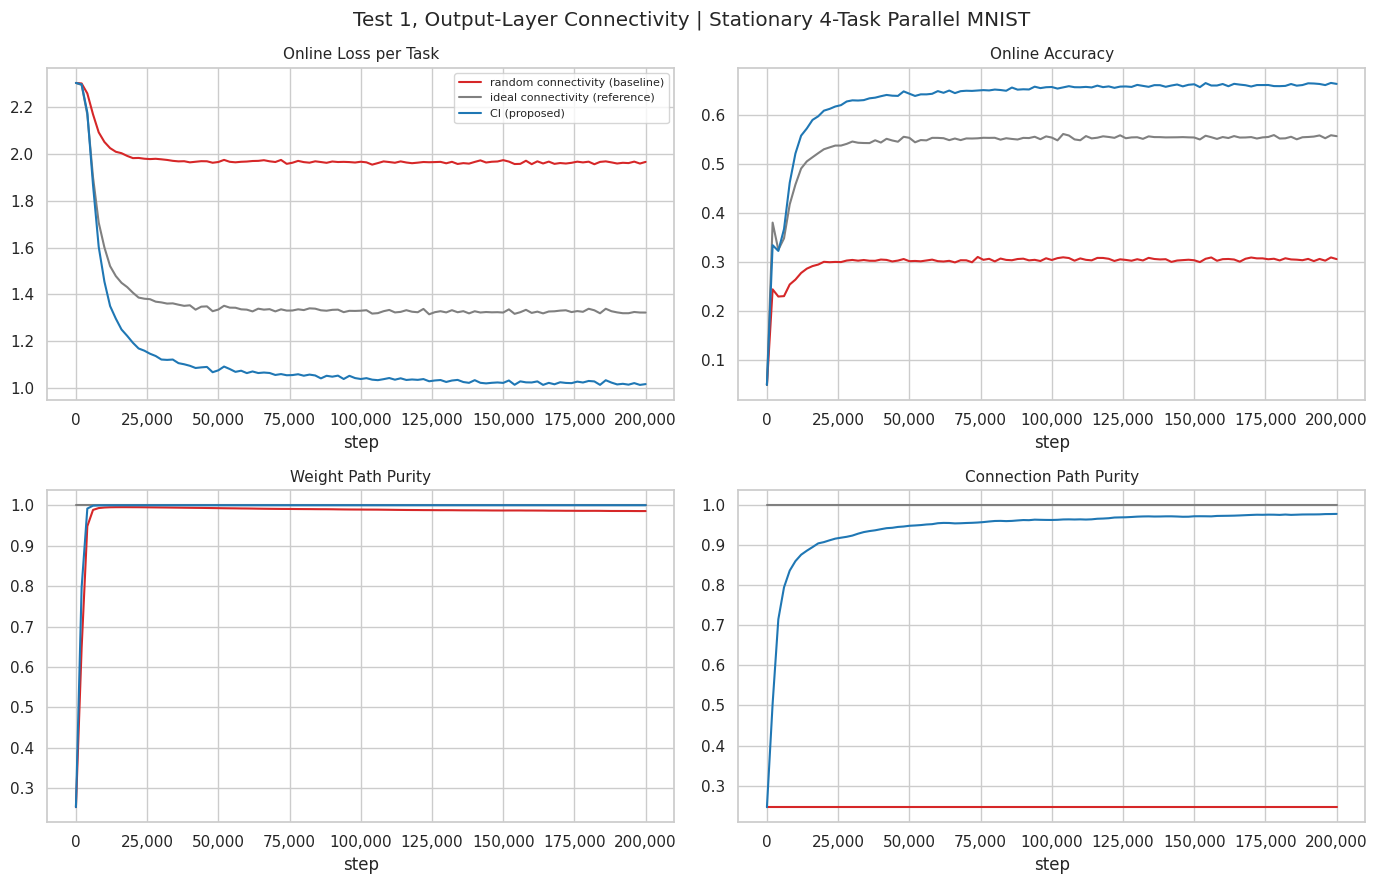

random connectivity (baseline)      loss 1.962   accuracy 0.306   weight purity 0.986   connection purity 0.246
ideal connectivity (reference)      loss 1.325   accuracy 0.555   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 1.020   accuracy 0.662   weight purity 1.000   connection purity 0.977
Share of the loss gap CI (proposed) closes: 1.48


In [8]:
output_runs = test_runs(init_output_test, 'output')
plot_runs(output_runs, 'Test 1, Output-Layer Connectivity')
summarize(output_runs)

## Test 2: input layer

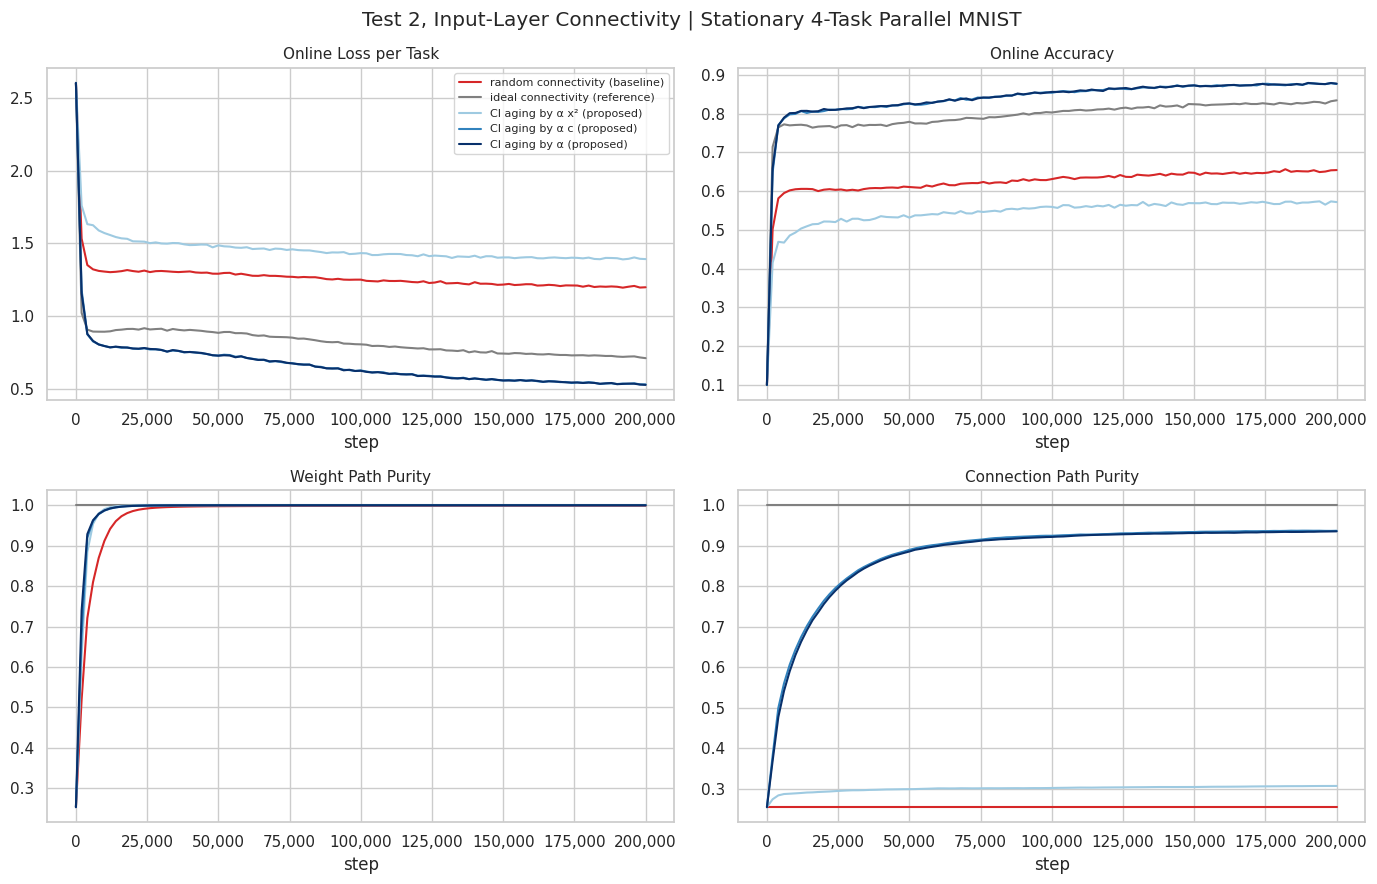

random connectivity (baseline)      loss 1.200   accuracy 0.652   weight purity 0.998   connection purity 0.254
ideal connectivity (reference)      loss 0.721   accuracy 0.829   weight purity 1.000   connection purity 1.000
CI aging by α x² (proposed)         loss 1.395   accuracy 0.571   weight purity 1.000   connection purity 0.306
CI aging by α c (proposed)          loss 0.534   accuracy 0.876   weight purity 1.000   connection purity 0.937
CI aging by α (proposed)            loss 0.534   accuracy 0.877   weight purity 1.000   connection purity 0.934
Share of the loss gap CI aging by α x² (proposed) closes: -0.41
Share of the loss gap CI aging by α c (proposed) closes: 1.39
Share of the loss gap CI aging by α (proposed) closes: 1.39


In [9]:
ages = {'CI aging by α x² (proposed)': 'input', 'CI aging by α c (proposed)': 'c', 'CI aging by α (proposed)': 'alpha'}
input_runs = {'random connectivity (baseline)': run(lambda key: init_input_test(key, False), 'input'),
              'ideal connectivity (reference)': run(lambda key: init_input_test(key, True), 'input')}
for label, age in ages.items():
    input_runs[label] = run(lambda key: init_input_test(key, False), 'input', prune=True, age=age)
plot_runs(input_runs, 'Test 2, Input-Layer Connectivity')
summarize(input_runs, ages)

## Test 3: both layers

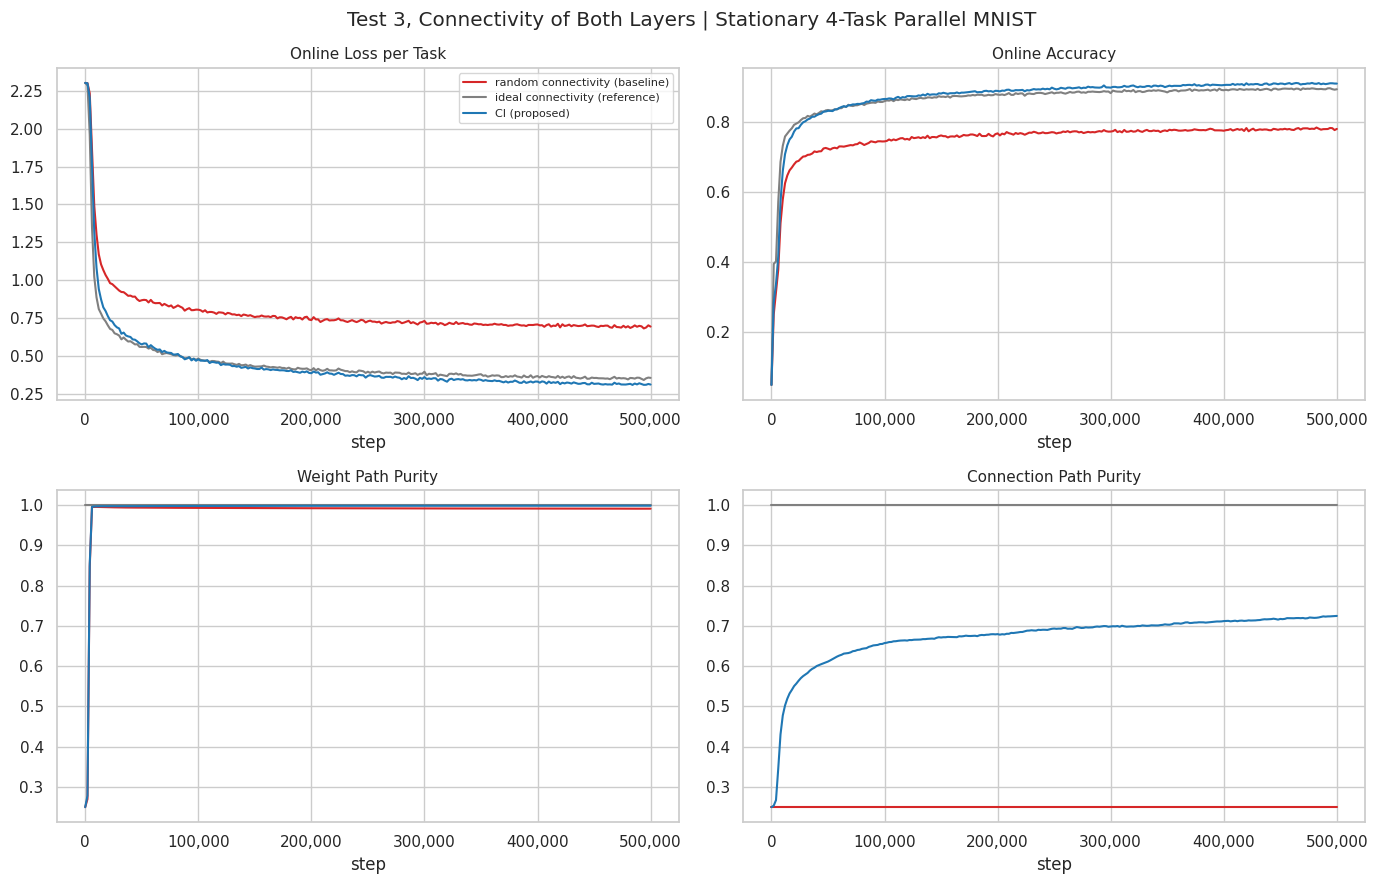

random connectivity (baseline)      loss 0.693   accuracy 0.781   weight purity 0.991   connection purity 0.250
ideal connectivity (reference)      loss 0.351   accuracy 0.896   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 0.313   accuracy 0.911   weight purity 0.999   connection purity 0.721
Share of the loss gap CI (proposed) closes: 1.11


In [10]:
both_runs = test_runs(init_both_test, 'both')
plot_runs(both_runs, 'Test 3, Connectivity of Both Layers')
summarize(both_runs)

## Test 4: both layers with shadow weights

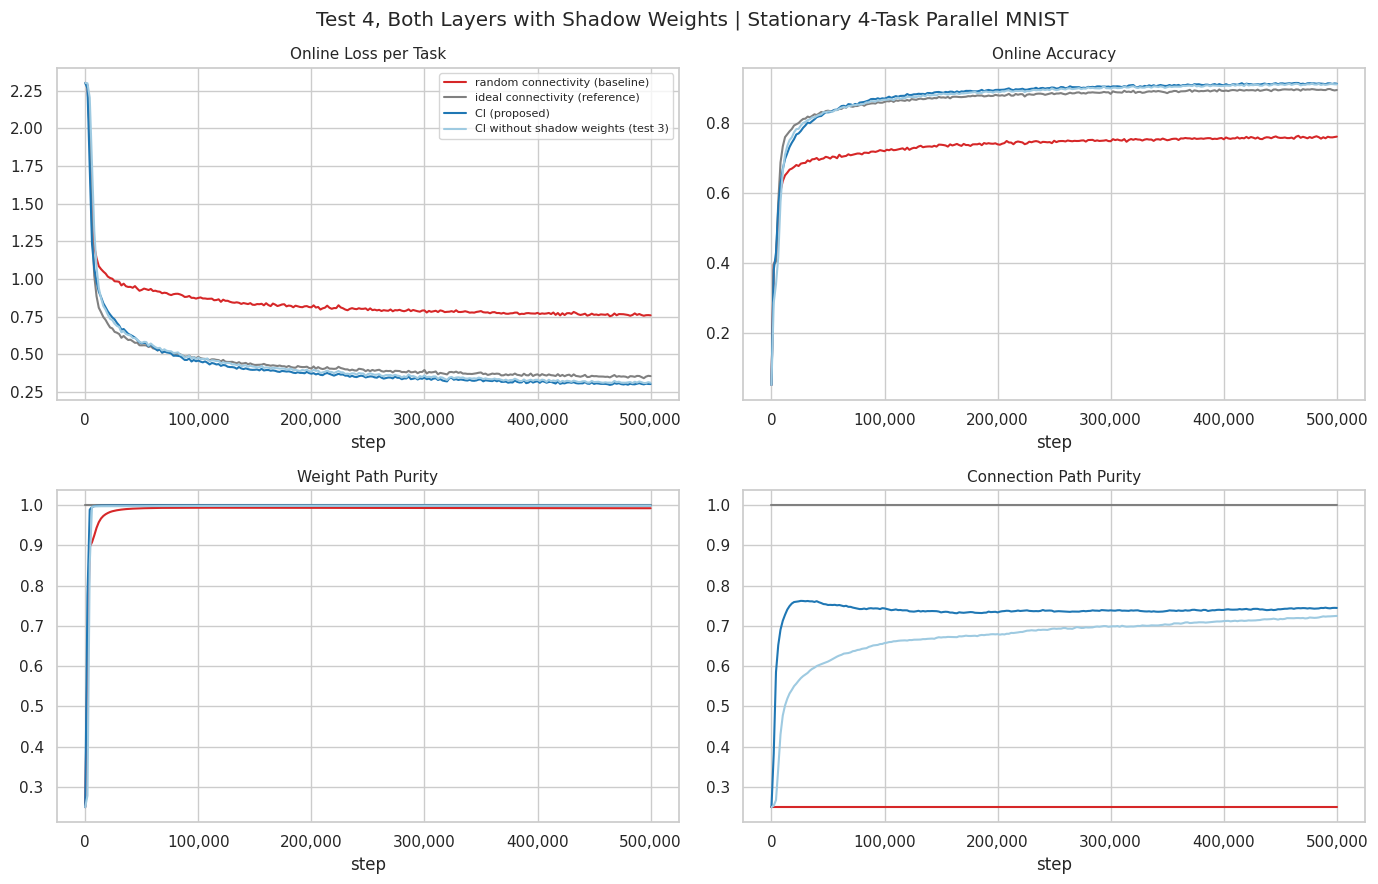

random connectivity (baseline)      loss 0.762   accuracy 0.759   weight purity 0.992   connection purity 0.250
ideal connectivity (reference)      loss 0.351   accuracy 0.896   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 0.302   accuracy 0.913   weight purity 0.999   connection purity 0.744
CI without shadow weights (test 3)  loss 0.313   accuracy 0.911   weight purity 0.999   connection purity 0.721
Share of the loss gap CI (proposed) closes: 1.12


In [11]:
shadow_runs = {'random connectivity (baseline)': run(lambda key: init_shadow_test(key, False), 'both'),
               'ideal connectivity (reference)': both_runs['ideal connectivity (reference)'],
               'CI (proposed)': run(lambda key: init_shadow_test(key, False), 'both', prune=True, shadow=True),
               'CI without shadow weights (test 3)': both_runs['CI (proposed)']}
plot_runs(shadow_runs, 'Test 4, Both Layers with Shadow Weights')
summarize(shadow_runs)

## Test 5: both layers without regrowth after 100k steps

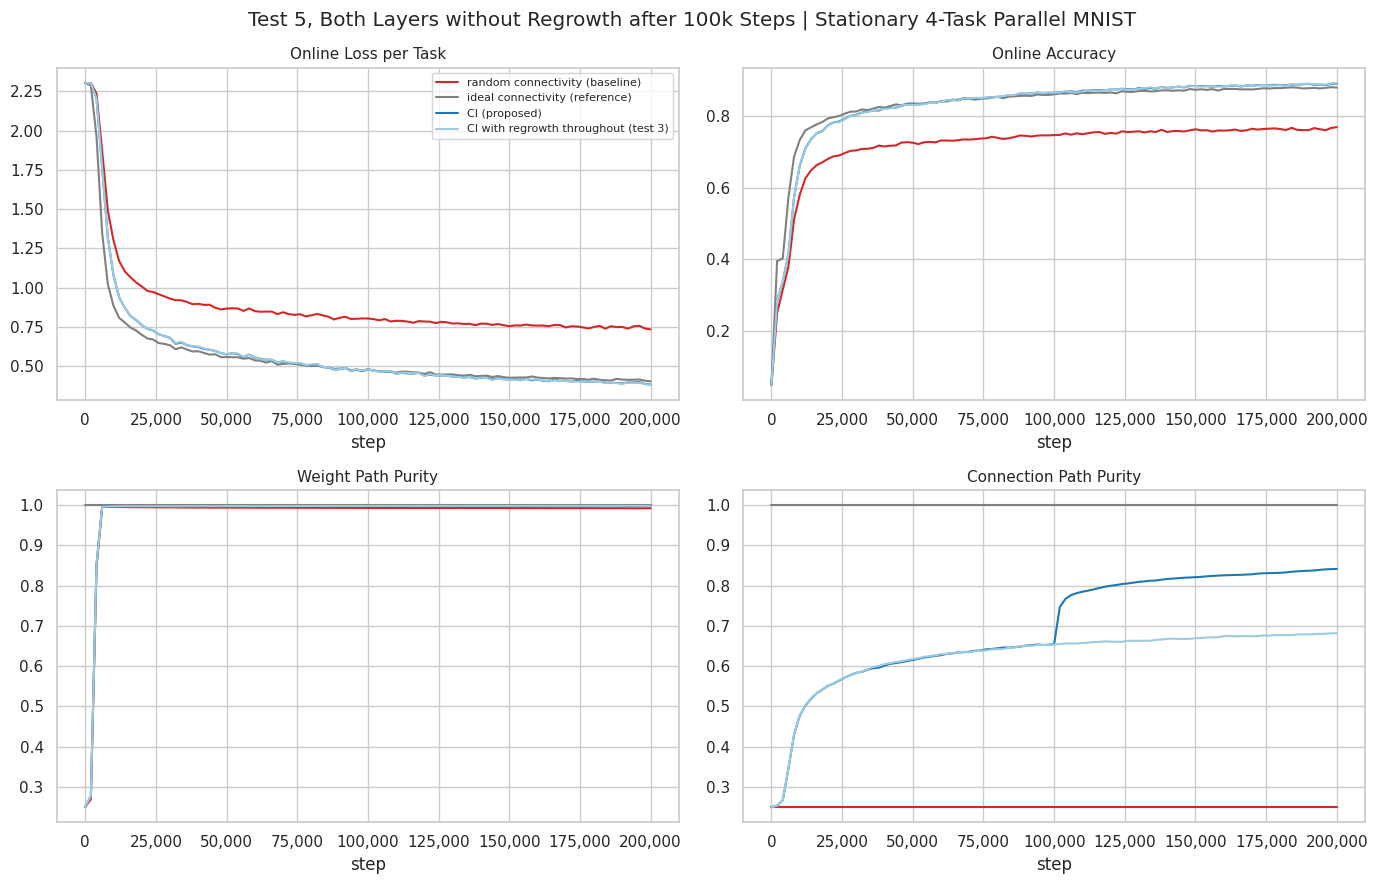

random connectivity (baseline)      loss 0.748   accuracy 0.764   weight purity 0.992   connection purity 0.250
ideal connectivity (reference)      loss 0.413   accuracy 0.879   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 0.395   accuracy 0.888   weight purity 0.998   connection purity 0.838
CI with regrowth throughout (test 3) loss 0.393   accuracy 0.888   weight purity 0.998   connection purity 0.680
Share of the loss gap CI (proposed) closes: 1.05


In [12]:
regrowth_runs = {'random connectivity (baseline)': both_runs['random connectivity (baseline)'],
                 'ideal connectivity (reference)': both_runs['ideal connectivity (reference)'],
                 'CI (proposed)': run(lambda key: init_both_test(key, False), 'both', prune=True,
                                      regrow_until=100_000),
                 'CI with regrowth throughout (test 3)': both_runs['CI (proposed)']}
plot_runs(regrowth_runs, 'Test 5, Both Layers without Regrowth after 100k Steps')
summarize(regrowth_runs)

## Test 6: both layers with shadow weights and an adaptive bar

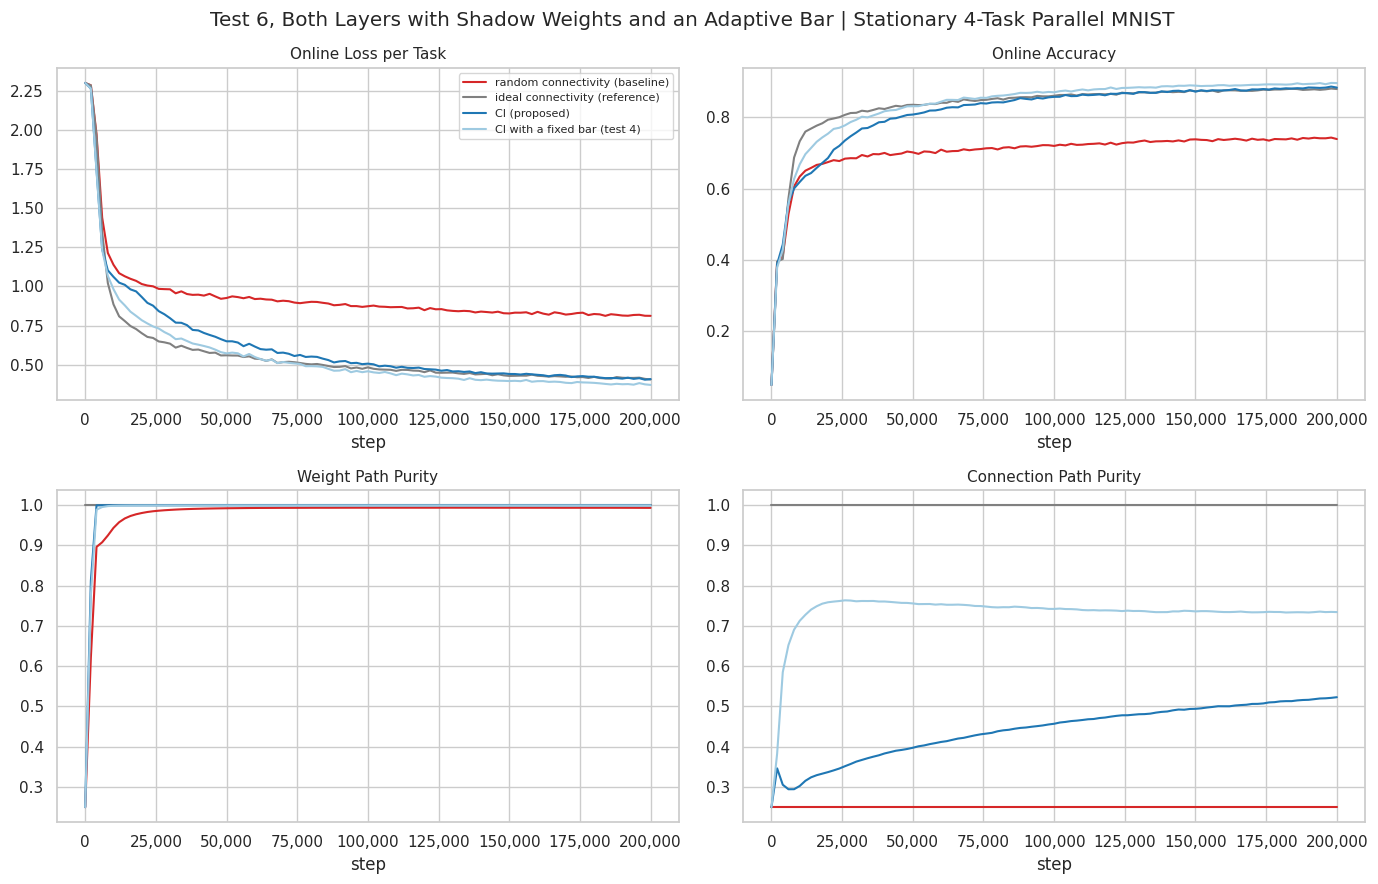

random connectivity (baseline)      loss 0.816   accuracy 0.741   weight purity 0.993   connection purity 0.250
ideal connectivity (reference)      loss 0.413   accuracy 0.879   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 0.412   accuracy 0.883   weight purity 1.000   connection purity 0.518
CI with a fixed bar (test 4)        loss 0.376   accuracy 0.894   weight purity 0.999   connection purity 0.734
Share of the loss gap CI (proposed) closes: 1.00


In [13]:
adaptive_runs = {'random connectivity (baseline)': shadow_runs['random connectivity (baseline)'],
                 'ideal connectivity (reference)': both_runs['ideal connectivity (reference)'],
                 'CI (proposed)': run(lambda key: init_shadow_test(key, False), 'both', prune=True, shadow=True,
                                      adaptive=True),
                 'CI with a fixed bar (test 4)': shadow_runs['CI (proposed)']}
plot_runs(adaptive_runs, 'Test 6, Both Layers with Shadow Weights and an Adaptive Bar')
summarize(adaptive_runs)

## Baseline 1: SET

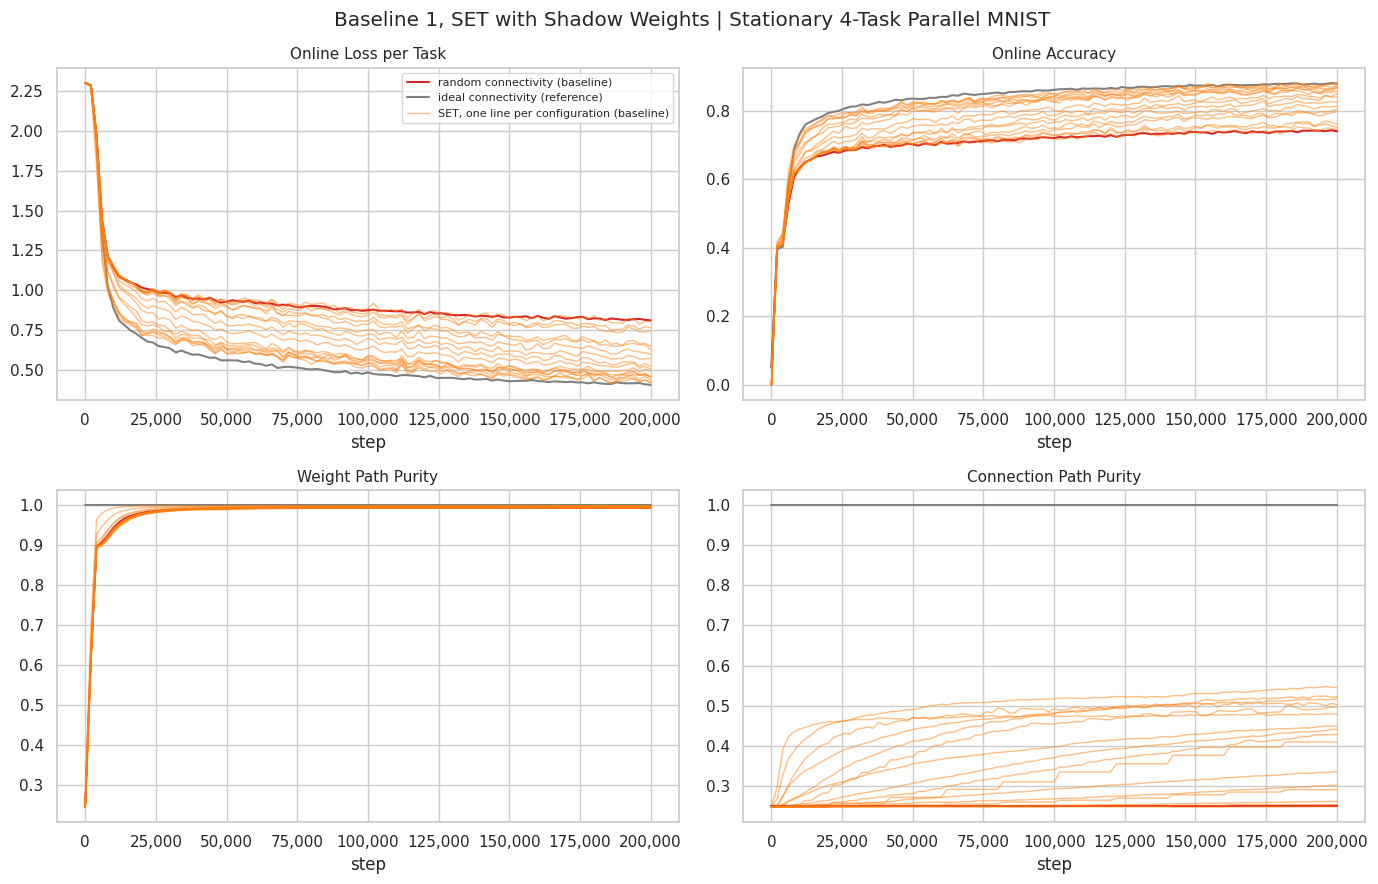

In [ ]:
SET_PERIODS = (100, 1_000, 5_000, 20_000)     # steps between prune-and-regrow events
SET_ZETAS = (0.01, 0.03, 0.1, 0.3)             # share of each layer's connections replaced at each event
periods, zetas = (a.ravel() for a in jnp.meshgrid(jnp.array(SET_PERIODS), jnp.array(SET_ZETAS), indexing='ij'))
seed_keys = tuple(jax.random.split(jax.random.PRNGKey(i), N_SEEDS)[0] for i in (0, 1))     # seed 0's, as in run
set_sweep = jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda period, zeta: train(
    *seed_keys, lambda key: init_shadow_test(key, False), 'both', True, True, 'c', None, False,
    (period, zeta))))(periods, zetas))
plot_runs({'random connectivity (baseline)': shadow_runs['random connectivity (baseline)'],
           'ideal connectivity (reference)': both_runs['ideal connectivity (reference)']},
          'Baseline 1, SET with Shadow Weights', sweep=('SET, one line per configuration (baseline)', set_sweep))

## Baseline 2: layer-wide utility

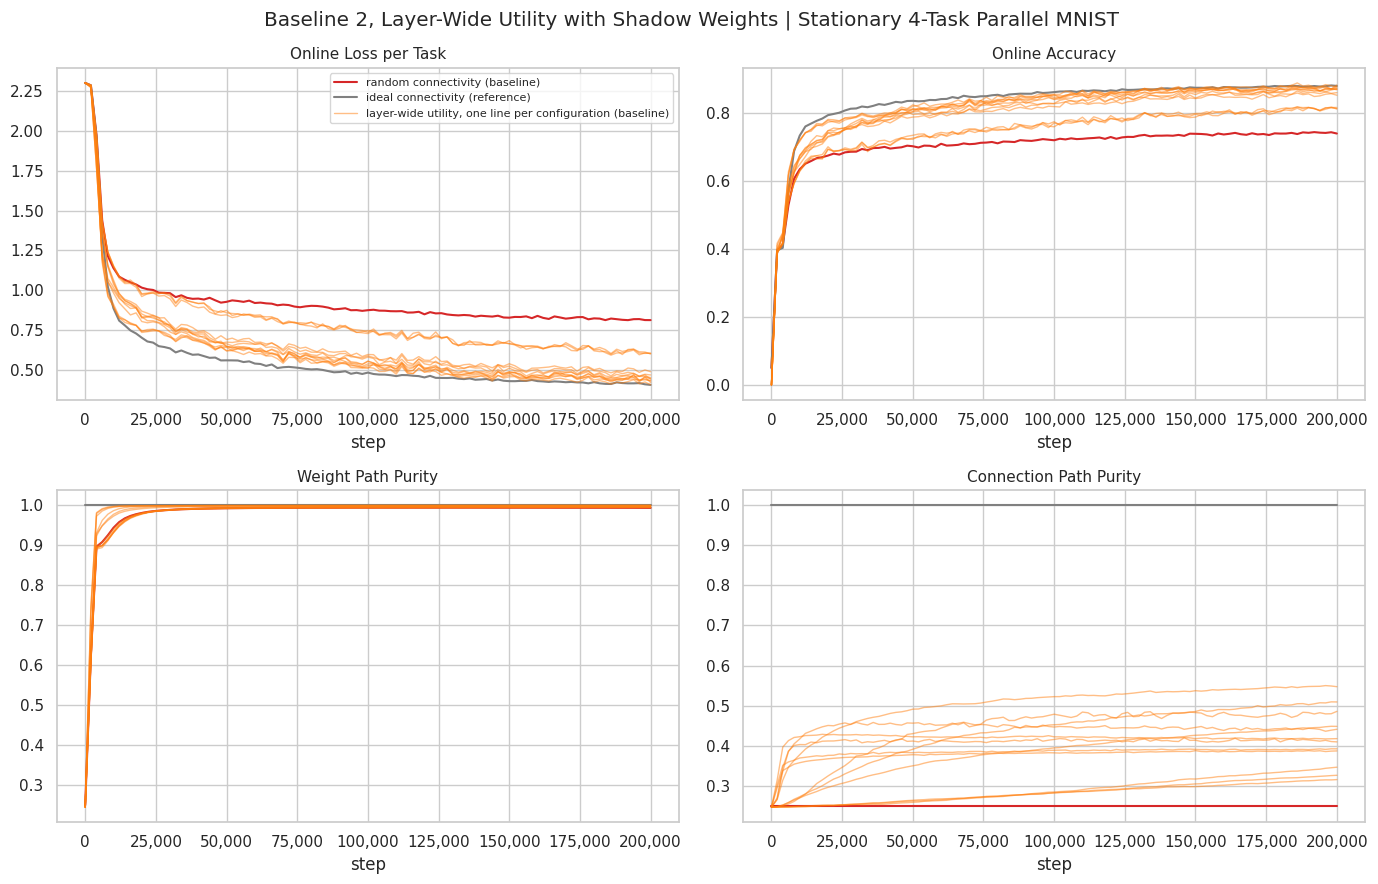

In [ ]:
UTILITY_RATES = (1e-5, 1e-4, 1e-3, 1e-2)      # share of the layer's connections cut per step
UTILITY_DECAYS = (0.9, 0.99, 0.999)           # decay of each connection's utility trace
rates, decays = (a.ravel() for a in jnp.meshgrid(jnp.array(UTILITY_RATES), jnp.array(UTILITY_DECAYS),
                                                 indexing='ij'))
layer_sweep = jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda rate, decay: train(
    *seed_keys, init_spread_test, 'both', True, True, 'c', None, False,
    utility_rule=(False, rate, decay))))(rates, decays))
plot_runs({'random connectivity (baseline)': shadow_runs['random connectivity (baseline)'],
           'ideal connectivity (reference)': both_runs['ideal connectivity (reference)']},
          'Baseline 2, Layer-Wide Utility with Shadow Weights',
          sweep=('layer-wide utility, one line per configuration (baseline)', layer_sweep))

## Baseline 3: per-unit utility

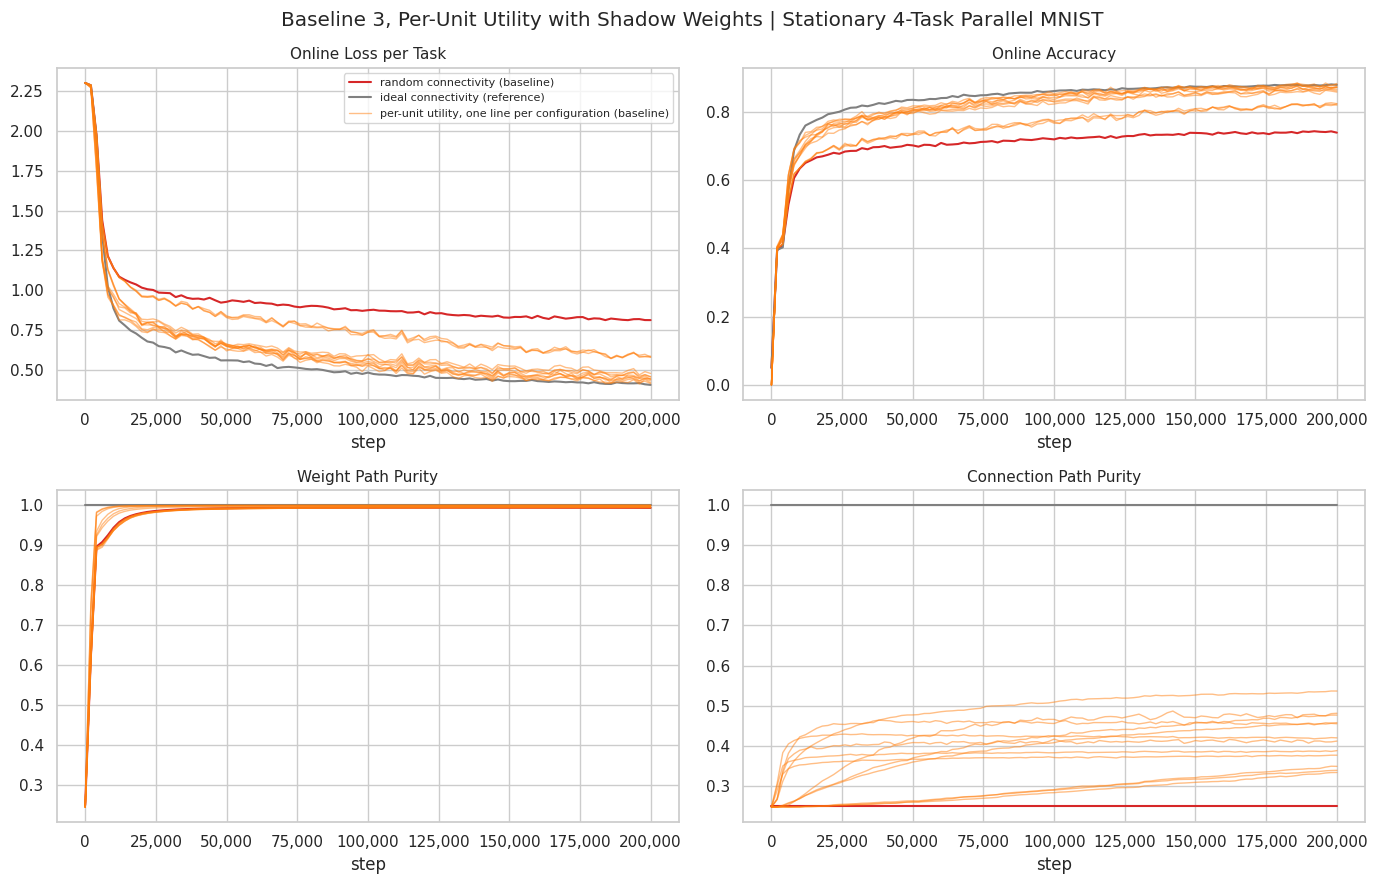

In [ ]:
unit_sweep = jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda rate, decay: train(
    *seed_keys, lambda key: init_shadow_test(key, False), 'both', True, True, 'c', None, False,
    utility_rule=(True, rate, decay))))(rates, decays))
plot_runs({'random connectivity (baseline)': shadow_runs['random connectivity (baseline)'],
           'ideal connectivity (reference)': both_runs['ideal connectivity (reference)']},
          'Baseline 3, Per-Unit Utility with Shadow Weights',
          sweep=('per-unit utility, one line per configuration (baseline)', unit_sweep))

## Baseline 4: DEEP R

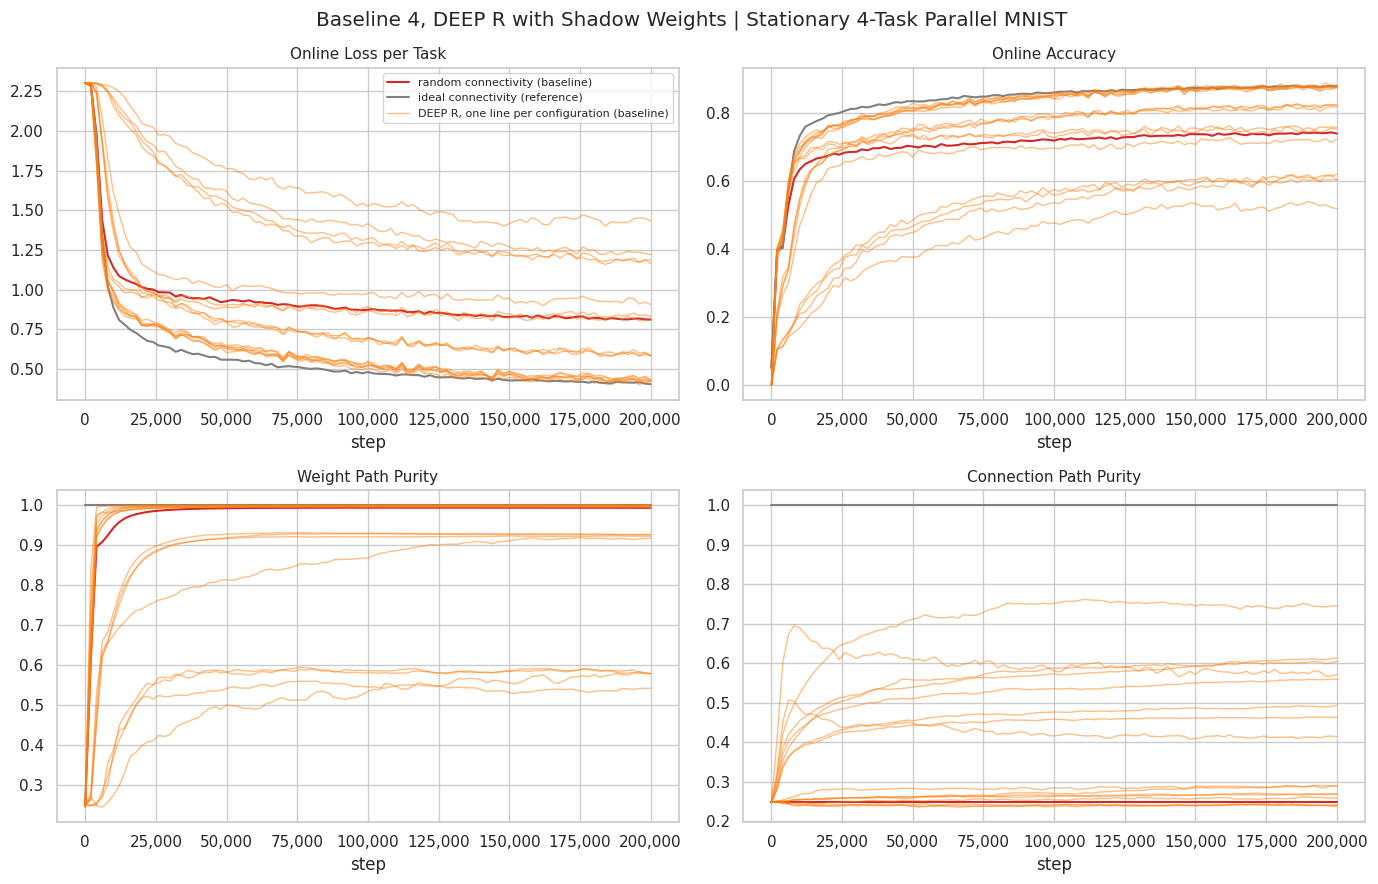

In [ ]:
DEEP_R_L1S = (1e-5, 1e-4, 1e-3, 1e-2)             # L1 coefficient on each connection's magnitude
DEEP_R_TEMPERATURES = (0.0, 1e-7, 1e-5, 1e-3)      # temperature of the noise
l1s, temperatures = (a.ravel() for a in jnp.meshgrid(jnp.array(DEEP_R_L1S), jnp.array(DEEP_R_TEMPERATURES),
                                                     indexing='ij'))
deep_r_sweep = jax.tree.map(np.asarray, jax.jit(jax.vmap(lambda l1, temperature: train(
    *seed_keys, init_spread_test, 'both', True, True, 'c', None, False,
    deep_r=(l1, temperature))))(l1s, temperatures))
plot_runs({'random connectivity (baseline)': shadow_runs['random connectivity (baseline)'],
           'ideal connectivity (reference)': both_runs['ideal connectivity (reference)']},
          'Baseline 4, DEEP R with Shadow Weights',
          sweep=('DEEP R, one line per configuration (baseline)', deep_r_sweep))

## Results

Over the last 10% of training, means over 5 seeds.

- **Test 1, output layer: H1 and H2 held.** CI's connection path purity is 0.977, against 0.246 with random
  connectivity. Its loss per task is 1.02, below both random connectivity (1.96) and ideal connectivity (1.33).
- **Test 2, input layer.** Aging by $\alpha c$ and by $\alpha$ give the same results, and H1 and H2 held for both:
  connection path purity 0.937 and 0.934, against 0.254 with random connectivity, and loss per task 0.53, below both
  random connectivity (1.20) and ideal connectivity (0.72). Aging by $\alpha x^2$, H1 and H2 failed: purity 0.306 and
  loss 1.40, because slots on never-lit pixels never age, so they are never cut and collect most of the slots.
- **Test 3, both layers: H1 failed, H2 held.** CI's connection path purity is 0.680, against 0.250 with random
  connectivity, and still rising slowly at 200k steps. Its loss per task is 0.39, below both random connectivity
  (0.75) and ideal connectivity (0.41).
- **Test 4, both layers with shadow weights: H1 failed, H2 and H3 held.** CI's connection path purity is 0.734,
  against 0.680 without shadow weights (test 3). It peaks at about 0.76 by 25k steps and then declines slightly. Its
  loss per task is 0.38, below both random connectivity with shadow weights (0.82) and ideal connectivity (0.41).
  Shadow weights make random connectivity worse than in test 3 (0.82 against 0.75).
- **Test 5, both layers without regrowth after 100k steps.** CI's connection path purity jumps from about 0.655 to
  0.76 within a few thousand steps of regrowth stopping, then rises slowly to 0.838, still rising at 200k, against 0.680
  with regrowth throughout (test 3). So about half of test 3's remaining impurity is new connections still being added,
  and the rest is connections that are cut slowly or not at all. Loss per task is unchanged (0.39).
- **Test 6, both layers with shadow weights and an adaptive bar: H1 and H4 failed, H2 held.** CI's connection path
  purity is 0.518, against 0.734 with the fixed bar (test 4), rising slowly from about 0.3 throughout training and
  still rising at 200k. Its loss per task is 0.41, against 0.38 with the fixed bar, the same as ideal connectivity
  (0.41) and below random connectivity with shadow weights (0.82).
- **Baseline 1, SET: every configuration is worse than CI with shadow weights (test 4) in both purity and loss.** The
  highest connection path purity is 0.54 (every 100 steps, $\zeta$ = 0.1), against CI's 0.734, and the lowest loss per
  task 0.43 (every 100 steps, $\zeta$ = 0.3), against CI's 0.38. More frequent and larger replacements do better, up
  to $\zeta$ = 0.1 for purity; the slowest (every 20,000 steps, $\zeta$ = 0.01) stays at random connectivity (purity
  0.25, loss 0.81). One seed per configuration.
- **Baselines 2 and 3, layer-wide and per-unit utility: every configuration is worse than CI with shadow weights (test
  4) in both purity and loss, and the two baselines are nearly the same.** The best configuration of each, $r$ =
  10⁻³ and $\lambda$ = 0.9, reaches connection path purity 0.55 (layer-wide) and 0.53 (per-unit), against CI's 0.734,
  and loss per task 0.42 for both, against CI's 0.38, about the same as SET's best. $r$ = 10⁻⁵ barely leaves random
  connectivity (purity 0.31 to 0.34). One seed per configuration.
- **Baseline 4, DEEP R: the best configuration matches CI with shadow weights (test 4) in purity but not in loss.**
  With $\lambda$ = 10⁻³ and no noise, connection path purity is 0.75, against CI's 0.734 (one seed against five), and
  loss per task 0.42, against CI's 0.38. Noise only hurts: at every $\lambda$, $T$ = 0 is best, and $T \ge 10^{-5}$
  leaves purity near random (0.24 to 0.29), with loss up to 1.43 at $T$ = 10⁻³. $\lambda$ = 10⁻² cuts too much (loss
  0.82 or more). One seed per configuration.
- **CI matches or beats ideal connectivity in every test**, likely because it chooses which of its task's sources
  each unit reads, while ideal connectivity reads a fixed random subset of them.
- **Weight path purity is near 1 even with random connectivity** (0.99 or more), because Autostep keeps the weights
  of cross-task connections small. Connection path purity is the metric that shows whether connectivity was learned.

**Diagnostic for test 3** (CI only, 5 seeds, run separately from this notebook). At 200k steps the impurity is spread
over both layers: a hidden unit's top task holds 86% of its inputs and 81% of its outputs on average, and for 95% of
hidden units the two top tasks agree.

## Temporary: dense and pruned from dense, on one task

How well can this many hidden units do at this connection budget? Both runs are on a single MNIST task (784 → 50 → 10),
with test 3's learner and start, no shadow weights and nothing cut:
- **Dense:** every hidden unit reads all 784 pixels and every output all 50 hidden units.
- **Pruned from dense:** each seed's dense net at 200k steps keeps each hidden unit's 64 largest-$|w|$ inputs and each
  output's 20 largest, a fourth of the 4-task budget, and a fresh net is trained from scratch on that fixed
  connectivity, on the same images.

Under ideal connectivity the tasks share nothing, so its loss per task is what one task alone gets. The plot compares
both runs with test 3's random and ideal connectivity and test 4's CI, which are 4-task runs. On one task, path purity
is 1.

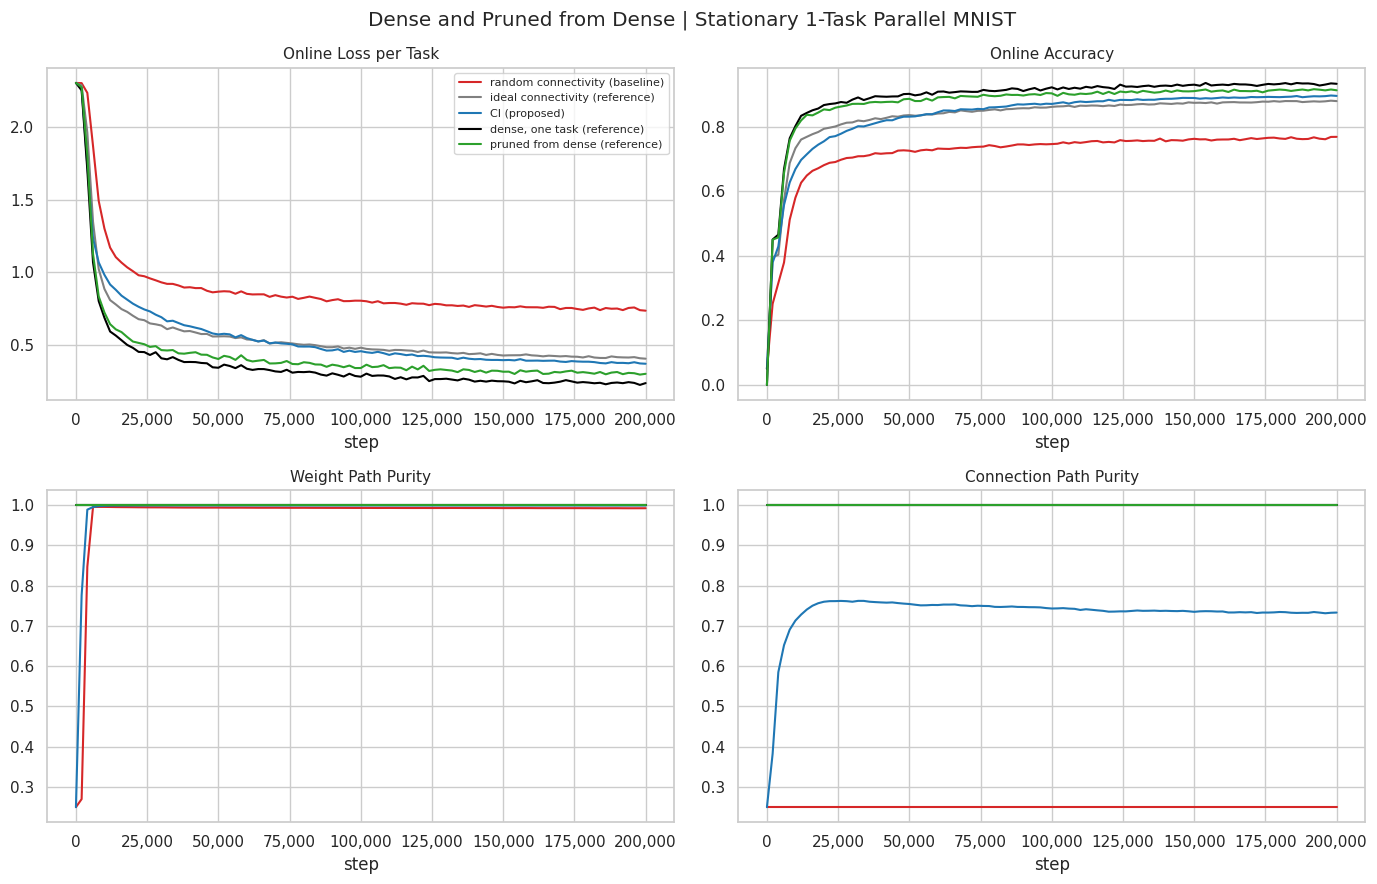

random connectivity (baseline)      loss 0.748   accuracy 0.764   weight purity 0.992   connection purity 0.250
ideal connectivity (reference)      loss 0.413   accuracy 0.878   weight purity 1.000   connection purity 1.000
CI (proposed)                       loss 0.377   accuracy 0.894   weight purity 0.999   connection purity 0.733
dense, one task (reference)         loss 0.237   accuracy 0.932   weight purity 1.000   connection purity 1.000
pruned from dense (reference)       loss 0.305   accuracy 0.913   weight purity 1.000   connection purity 1.000
Share of the loss gap CI (proposed) closes: 1.11


In [ ]:
# This section runs on one task, so it changes the problem's globals: run it last.
N_TASKS = 1
N_INPUTS, N_HIDDEN, N_OUTPUTS = N_PIXELS, HIDDEN_PER_TASK, N_CLASSES
N_SOURCES = (N_INPUTS, N_HIDDEN)
INPUT_TASK, HIDDEN_TASK, OUTPUT_TASK = (jnp.zeros(n, jnp.int32) for n in (N_INPUTS, N_HIDDEN, N_OUTPUTS))


def init_dense_test(key):
    # Every hidden unit reads all pixels and every output all hidden units. Input weights and biases start
    # U(-alpha_0, alpha_0) and output weights and biases at 0, as in test 3.
    src_in = jnp.tile(jnp.arange(N_INPUTS), (N_HIDDEN, 1))
    src_out = jnp.tile(jnp.arange(N_HIDDEN), (N_OUTPUTS, 1))
    w_in = jax.random.uniform(key, (N_HIDDEN, N_INPUTS + 1), minval=-1.0, maxval=1.0) * AUTOSTEP_INIT_STEP_SIZE
    return new_net(key, w_in, src_in, jnp.zeros((N_OUTPUTS, N_HIDDEN + 1)), src_out, 'both')


def init_pruned_test(key, dense):
    # A fresh net, started as in test 3, in which each hidden unit reads the HIDDEN_FAN_IN sources with the largest |w|
    # in the trained dense net and each output the OUTPUT_FAN_IN largest.
    largest = lambda w, src, k: jnp.take_along_axis(src, jax.lax.top_k(jnp.abs(w[:, :-1]), k)[1], axis=1)
    return new_net(key, small_input_weights(key), largest(dense.w_in, dense.src_in, HIDDEN_FAN_IN),
                   jnp.zeros((N_OUTPUTS, OUTPUT_FAN_IN + 1)), largest(dense.w_out, dense.src_out, OUTPUT_FAN_IN),
                   'both')


def train_keeping_net(init_key, stream_key, init):
    # train() with fixed connectivity in both layers, also returning the net at the end.
    def step(carry, _):
        net, key = carry
        key, sample_key = jax.random.split(key)
        net, loss, accuracy = learn(net, *next_sample(sample_key), 'both', False)
        purities = [path_purity(*task_totals(net, value)) for value in (jnp.abs, jnp.ones_like)]
        return (net, key), dict(zip(METRICS, (loss, accuracy, *purities)))

    def window(carry, _):
        carry, values = jax.lax.scan(step, carry, length=WINDOW)
        return carry, jax.tree.map(jnp.mean, values)

    carry, first = step((init(init_key), stream_key), None)
    carry, rest = jax.lax.scan(window, carry, length=N_WINDOWS)
    return jax.tree.map(lambda f, r: jnp.concatenate([f[None], r]), first, rest), carry[0]


keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS), jax.random.split(jax.random.PRNGKey(1), N_SEEDS)
dense_records, dense_nets = jax.jit(jax.vmap(lambda a, b: train_keeping_net(a, b, init_dense_test)))(*keys)
pruned_records = jax.jit(jax.vmap(lambda a, b, dense: train(a, b, lambda key: init_pruned_test(key, dense), 'both',
                                                            False, False, 'c', None, False)))(*keys, dense_nets)

COLORS.update({'dense, one task (reference)': 'black', 'pruned from dense (reference)': 'tab:green'})
dense_runs = {'random connectivity (baseline)': both_runs['random connectivity (baseline)'],
              'ideal connectivity (reference)': both_runs['ideal connectivity (reference)'],
              'CI (proposed)': shadow_runs['CI (proposed)'],
              'dense, one task (reference)': jax.tree.map(np.asarray, dense_records),
              'pruned from dense (reference)': jax.tree.map(np.asarray, pruned_records)}
plot_runs(dense_runs, 'Dense and Pruned from Dense')
summarize(dense_runs)